# 🐧 Esercitazione 2 — Regressione, alberi e scelta degli iperparametri

**new ALF – Tutorato** · Corso di Laurea in Informatica · AA 2026/27

Nell'Esercitazione 1 abbiamo scritto un classificatore a mano, lo abbiamo valutato e abbiamo addestrato i primi alberi di decisione con scikit-learn. Oggi facciamo un passo avanti: vediamo la **regressione lineare**, gli **alberi di regressione** e come una regressione può servire anche a classificare. Poi torniamo agli alberi di classificazione e vediamo **come si sceglie un albero**: i suoi **iperparametri**, la **cross-validation** e la ricerca automatica con **`GridSearchCV`**.

Useremo il dataset **Palmer Penguins**: le misure di 344 pinguini di tre specie (Adelie, Chinstrap e Gentoo), raccolte tra il 2007 e il 2009 su tre isole dell'arcipelago Palmer, in Antartide.


> ### ⚠️ Prima di tutto: fai la tua copia
> Questo notebook è condiviso in **sola lettura**: puoi eseguirlo e modificarlo, ma le modifiche **non verranno salvate**.
> Vai su **File → Salva una copia in Drive**. Si aprirà una nuova scheda con la *tua* copia (la trovi poi su Google Drive, nella cartella *Colab Notebooks*): lavora lì.

### Come si usa questo notebook
- Ogni **cella** si esegue con **Shift + Invio** (o con il tasto ▶ a sinistra). Esegui le celle **in ordine**, dall'alto verso il basso.
- Le celle segnate con **✏️** sono esercizi: modifica il codice dove indicato. Quando sotto c'è un blocco **💡 Soluzione** chiuso, prova prima da solo. Le celle successive funzionano anche se lasci l'esercizio com'è.
- I box **🐍** spiegano le cose nuove di Python che incontriamo strada facendo.
- Le sezioni segnate con **⏩** sono approfondimenti.
- I box **📋** dicono quale problema stiamo risolvendo. I dati sono sempre gli stessi pinguini: cambia la **domanda**, e con lei il target `y`, le feature `X` e il modo di valutare il modello.
- I box **🤔** sono domande su cui riflettere (spesso con la risposta chiusa sotto), i **📌** i concetti chiave.
- **🔒 / 🔓**: il test set serve a **valutare il modello finale**. Quando dobbiamo **scegliere** un modello resta chiuso, e si apre una volta sola, alla fine.
- Se qualcosa si rompe: menu **Runtime → Riavvia sessione ed esegui tutto** (*Restart session and run all*).

In [1]:
#@title ⚙️ Setup: esegui questa cella per prima (crea il file con i dati)
# Questa cella scrive nel workspace di Colab il file "pinguini.csv". Puoi vederlo nel pannello 📁 a sinistra.
# Nota: il workspace di Colab si svuota quando la sessione termina,
# quindi questa cella va rieseguita ogni volta che riapri il notebook.
#
# Dati: Palmer Penguins (Gorman, Williams & Fraser, 2014), raccolti alla Palmer Station (Antartide)
# e distribuiti con licenza CC0 dal pacchetto palmerpenguins di A. Horst, A. Hill e K. Gorman.
# Nomi delle colonne e valori del sesso tradotti in italiano.

PINGUINI_CSV = """specie,isola,becco_lunghezza,becco_profondita,pinna,peso,sesso
Adelie,Torgersen,39.1,18.7,181,3750,maschio
Adelie,Torgersen,39.5,17.4,186,3800,femmina
Adelie,Torgersen,40.3,18,195,3250,femmina
Adelie,Torgersen,,,,,
Adelie,Torgersen,36.7,19.3,193,3450,femmina
Adelie,Torgersen,39.3,20.6,190,3650,maschio
Adelie,Torgersen,38.9,17.8,181,3625,femmina
Adelie,Torgersen,39.2,19.6,195,4675,maschio
Adelie,Torgersen,34.1,18.1,193,3475,
Adelie,Torgersen,42,20.2,190,4250,
Adelie,Torgersen,37.8,17.1,186,3300,
Adelie,Torgersen,37.8,17.3,180,3700,
Adelie,Torgersen,41.1,17.6,182,3200,femmina
Adelie,Torgersen,38.6,21.2,191,3800,maschio
Adelie,Torgersen,34.6,21.1,198,4400,maschio
Adelie,Torgersen,36.6,17.8,185,3700,femmina
Adelie,Torgersen,38.7,19,195,3450,femmina
Adelie,Torgersen,42.5,20.7,197,4500,maschio
Adelie,Torgersen,34.4,18.4,184,3325,femmina
Adelie,Torgersen,46,21.5,194,4200,maschio
Adelie,Biscoe,37.8,18.3,174,3400,femmina
Adelie,Biscoe,37.7,18.7,180,3600,maschio
Adelie,Biscoe,35.9,19.2,189,3800,femmina
Adelie,Biscoe,38.2,18.1,185,3950,maschio
Adelie,Biscoe,38.8,17.2,180,3800,maschio
Adelie,Biscoe,35.3,18.9,187,3800,femmina
Adelie,Biscoe,40.6,18.6,183,3550,maschio
Adelie,Biscoe,40.5,17.9,187,3200,femmina
Adelie,Biscoe,37.9,18.6,172,3150,femmina
Adelie,Biscoe,40.5,18.9,180,3950,maschio
Adelie,Dream,39.5,16.7,178,3250,femmina
Adelie,Dream,37.2,18.1,178,3900,maschio
Adelie,Dream,39.5,17.8,188,3300,femmina
Adelie,Dream,40.9,18.9,184,3900,maschio
Adelie,Dream,36.4,17,195,3325,femmina
Adelie,Dream,39.2,21.1,196,4150,maschio
Adelie,Dream,38.8,20,190,3950,maschio
Adelie,Dream,42.2,18.5,180,3550,femmina
Adelie,Dream,37.6,19.3,181,3300,femmina
Adelie,Dream,39.8,19.1,184,4650,maschio
Adelie,Dream,36.5,18,182,3150,femmina
Adelie,Dream,40.8,18.4,195,3900,maschio
Adelie,Dream,36,18.5,186,3100,femmina
Adelie,Dream,44.1,19.7,196,4400,maschio
Adelie,Dream,37,16.9,185,3000,femmina
Adelie,Dream,39.6,18.8,190,4600,maschio
Adelie,Dream,41.1,19,182,3425,maschio
Adelie,Dream,37.5,18.9,179,2975,
Adelie,Dream,36,17.9,190,3450,femmina
Adelie,Dream,42.3,21.2,191,4150,maschio
Adelie,Biscoe,39.6,17.7,186,3500,femmina
Adelie,Biscoe,40.1,18.9,188,4300,maschio
Adelie,Biscoe,35,17.9,190,3450,femmina
Adelie,Biscoe,42,19.5,200,4050,maschio
Adelie,Biscoe,34.5,18.1,187,2900,femmina
Adelie,Biscoe,41.4,18.6,191,3700,maschio
Adelie,Biscoe,39,17.5,186,3550,femmina
Adelie,Biscoe,40.6,18.8,193,3800,maschio
Adelie,Biscoe,36.5,16.6,181,2850,femmina
Adelie,Biscoe,37.6,19.1,194,3750,maschio
Adelie,Biscoe,35.7,16.9,185,3150,femmina
Adelie,Biscoe,41.3,21.1,195,4400,maschio
Adelie,Biscoe,37.6,17,185,3600,femmina
Adelie,Biscoe,41.1,18.2,192,4050,maschio
Adelie,Biscoe,36.4,17.1,184,2850,femmina
Adelie,Biscoe,41.6,18,192,3950,maschio
Adelie,Biscoe,35.5,16.2,195,3350,femmina
Adelie,Biscoe,41.1,19.1,188,4100,maschio
Adelie,Torgersen,35.9,16.6,190,3050,femmina
Adelie,Torgersen,41.8,19.4,198,4450,maschio
Adelie,Torgersen,33.5,19,190,3600,femmina
Adelie,Torgersen,39.7,18.4,190,3900,maschio
Adelie,Torgersen,39.6,17.2,196,3550,femmina
Adelie,Torgersen,45.8,18.9,197,4150,maschio
Adelie,Torgersen,35.5,17.5,190,3700,femmina
Adelie,Torgersen,42.8,18.5,195,4250,maschio
Adelie,Torgersen,40.9,16.8,191,3700,femmina
Adelie,Torgersen,37.2,19.4,184,3900,maschio
Adelie,Torgersen,36.2,16.1,187,3550,femmina
Adelie,Torgersen,42.1,19.1,195,4000,maschio
Adelie,Torgersen,34.6,17.2,189,3200,femmina
Adelie,Torgersen,42.9,17.6,196,4700,maschio
Adelie,Torgersen,36.7,18.8,187,3800,femmina
Adelie,Torgersen,35.1,19.4,193,4200,maschio
Adelie,Dream,37.3,17.8,191,3350,femmina
Adelie,Dream,41.3,20.3,194,3550,maschio
Adelie,Dream,36.3,19.5,190,3800,maschio
Adelie,Dream,36.9,18.6,189,3500,femmina
Adelie,Dream,38.3,19.2,189,3950,maschio
Adelie,Dream,38.9,18.8,190,3600,femmina
Adelie,Dream,35.7,18,202,3550,femmina
Adelie,Dream,41.1,18.1,205,4300,maschio
Adelie,Dream,34,17.1,185,3400,femmina
Adelie,Dream,39.6,18.1,186,4450,maschio
Adelie,Dream,36.2,17.3,187,3300,femmina
Adelie,Dream,40.8,18.9,208,4300,maschio
Adelie,Dream,38.1,18.6,190,3700,femmina
Adelie,Dream,40.3,18.5,196,4350,maschio
Adelie,Dream,33.1,16.1,178,2900,femmina
Adelie,Dream,43.2,18.5,192,4100,maschio
Adelie,Biscoe,35,17.9,192,3725,femmina
Adelie,Biscoe,41,20,203,4725,maschio
Adelie,Biscoe,37.7,16,183,3075,femmina
Adelie,Biscoe,37.8,20,190,4250,maschio
Adelie,Biscoe,37.9,18.6,193,2925,femmina
Adelie,Biscoe,39.7,18.9,184,3550,maschio
Adelie,Biscoe,38.6,17.2,199,3750,femmina
Adelie,Biscoe,38.2,20,190,3900,maschio
Adelie,Biscoe,38.1,17,181,3175,femmina
Adelie,Biscoe,43.2,19,197,4775,maschio
Adelie,Biscoe,38.1,16.5,198,3825,femmina
Adelie,Biscoe,45.6,20.3,191,4600,maschio
Adelie,Biscoe,39.7,17.7,193,3200,femmina
Adelie,Biscoe,42.2,19.5,197,4275,maschio
Adelie,Biscoe,39.6,20.7,191,3900,femmina
Adelie,Biscoe,42.7,18.3,196,4075,maschio
Adelie,Torgersen,38.6,17,188,2900,femmina
Adelie,Torgersen,37.3,20.5,199,3775,maschio
Adelie,Torgersen,35.7,17,189,3350,femmina
Adelie,Torgersen,41.1,18.6,189,3325,maschio
Adelie,Torgersen,36.2,17.2,187,3150,femmina
Adelie,Torgersen,37.7,19.8,198,3500,maschio
Adelie,Torgersen,40.2,17,176,3450,femmina
Adelie,Torgersen,41.4,18.5,202,3875,maschio
Adelie,Torgersen,35.2,15.9,186,3050,femmina
Adelie,Torgersen,40.6,19,199,4000,maschio
Adelie,Torgersen,38.8,17.6,191,3275,femmina
Adelie,Torgersen,41.5,18.3,195,4300,maschio
Adelie,Torgersen,39,17.1,191,3050,femmina
Adelie,Torgersen,44.1,18,210,4000,maschio
Adelie,Torgersen,38.5,17.9,190,3325,femmina
Adelie,Torgersen,43.1,19.2,197,3500,maschio
Adelie,Dream,36.8,18.5,193,3500,femmina
Adelie,Dream,37.5,18.5,199,4475,maschio
Adelie,Dream,38.1,17.6,187,3425,femmina
Adelie,Dream,41.1,17.5,190,3900,maschio
Adelie,Dream,35.6,17.5,191,3175,femmina
Adelie,Dream,40.2,20.1,200,3975,maschio
Adelie,Dream,37,16.5,185,3400,femmina
Adelie,Dream,39.7,17.9,193,4250,maschio
Adelie,Dream,40.2,17.1,193,3400,femmina
Adelie,Dream,40.6,17.2,187,3475,maschio
Adelie,Dream,32.1,15.5,188,3050,femmina
Adelie,Dream,40.7,17,190,3725,maschio
Adelie,Dream,37.3,16.8,192,3000,femmina
Adelie,Dream,39,18.7,185,3650,maschio
Adelie,Dream,39.2,18.6,190,4250,maschio
Adelie,Dream,36.6,18.4,184,3475,femmina
Adelie,Dream,36,17.8,195,3450,femmina
Adelie,Dream,37.8,18.1,193,3750,maschio
Adelie,Dream,36,17.1,187,3700,femmina
Adelie,Dream,41.5,18.5,201,4000,maschio
Chinstrap,Dream,46.5,17.9,192,3500,femmina
Chinstrap,Dream,50,19.5,196,3900,maschio
Chinstrap,Dream,51.3,19.2,193,3650,maschio
Chinstrap,Dream,45.4,18.7,188,3525,femmina
Chinstrap,Dream,52.7,19.8,197,3725,maschio
Chinstrap,Dream,45.2,17.8,198,3950,femmina
Chinstrap,Dream,46.1,18.2,178,3250,femmina
Chinstrap,Dream,51.3,18.2,197,3750,maschio
Chinstrap,Dream,46,18.9,195,4150,femmina
Chinstrap,Dream,51.3,19.9,198,3700,maschio
Chinstrap,Dream,46.6,17.8,193,3800,femmina
Chinstrap,Dream,51.7,20.3,194,3775,maschio
Chinstrap,Dream,47,17.3,185,3700,femmina
Chinstrap,Dream,52,18.1,201,4050,maschio
Chinstrap,Dream,45.9,17.1,190,3575,femmina
Chinstrap,Dream,50.5,19.6,201,4050,maschio
Chinstrap,Dream,50.3,20,197,3300,maschio
Chinstrap,Dream,58,17.8,181,3700,femmina
Chinstrap,Dream,46.4,18.6,190,3450,femmina
Chinstrap,Dream,49.2,18.2,195,4400,maschio
Chinstrap,Dream,42.4,17.3,181,3600,femmina
Chinstrap,Dream,48.5,17.5,191,3400,maschio
Chinstrap,Dream,43.2,16.6,187,2900,femmina
Chinstrap,Dream,50.6,19.4,193,3800,maschio
Chinstrap,Dream,46.7,17.9,195,3300,femmina
Chinstrap,Dream,52,19,197,4150,maschio
Chinstrap,Dream,50.5,18.4,200,3400,femmina
Chinstrap,Dream,49.5,19,200,3800,maschio
Chinstrap,Dream,46.4,17.8,191,3700,femmina
Chinstrap,Dream,52.8,20,205,4550,maschio
Chinstrap,Dream,40.9,16.6,187,3200,femmina
Chinstrap,Dream,54.2,20.8,201,4300,maschio
Chinstrap,Dream,42.5,16.7,187,3350,femmina
Chinstrap,Dream,51,18.8,203,4100,maschio
Chinstrap,Dream,49.7,18.6,195,3600,maschio
Chinstrap,Dream,47.5,16.8,199,3900,femmina
Chinstrap,Dream,47.6,18.3,195,3850,femmina
Chinstrap,Dream,52,20.7,210,4800,maschio
Chinstrap,Dream,46.9,16.6,192,2700,femmina
Chinstrap,Dream,53.5,19.9,205,4500,maschio
Chinstrap,Dream,49,19.5,210,3950,maschio
Chinstrap,Dream,46.2,17.5,187,3650,femmina
Chinstrap,Dream,50.9,19.1,196,3550,maschio
Chinstrap,Dream,45.5,17,196,3500,femmina
Chinstrap,Dream,50.9,17.9,196,3675,femmina
Chinstrap,Dream,50.8,18.5,201,4450,maschio
Chinstrap,Dream,50.1,17.9,190,3400,femmina
Chinstrap,Dream,49,19.6,212,4300,maschio
Chinstrap,Dream,51.5,18.7,187,3250,maschio
Chinstrap,Dream,49.8,17.3,198,3675,femmina
Chinstrap,Dream,48.1,16.4,199,3325,femmina
Chinstrap,Dream,51.4,19,201,3950,maschio
Chinstrap,Dream,45.7,17.3,193,3600,femmina
Chinstrap,Dream,50.7,19.7,203,4050,maschio
Chinstrap,Dream,42.5,17.3,187,3350,femmina
Chinstrap,Dream,52.2,18.8,197,3450,maschio
Chinstrap,Dream,45.2,16.6,191,3250,femmina
Chinstrap,Dream,49.3,19.9,203,4050,maschio
Chinstrap,Dream,50.2,18.8,202,3800,maschio
Chinstrap,Dream,45.6,19.4,194,3525,femmina
Chinstrap,Dream,51.9,19.5,206,3950,maschio
Chinstrap,Dream,46.8,16.5,189,3650,femmina
Chinstrap,Dream,45.7,17,195,3650,femmina
Chinstrap,Dream,55.8,19.8,207,4000,maschio
Chinstrap,Dream,43.5,18.1,202,3400,femmina
Chinstrap,Dream,49.6,18.2,193,3775,maschio
Chinstrap,Dream,50.8,19,210,4100,maschio
Chinstrap,Dream,50.2,18.7,198,3775,femmina
Gentoo,Biscoe,46.1,13.2,211,4500,femmina
Gentoo,Biscoe,50,16.3,230,5700,maschio
Gentoo,Biscoe,48.7,14.1,210,4450,femmina
Gentoo,Biscoe,50,15.2,218,5700,maschio
Gentoo,Biscoe,47.6,14.5,215,5400,maschio
Gentoo,Biscoe,46.5,13.5,210,4550,femmina
Gentoo,Biscoe,45.4,14.6,211,4800,femmina
Gentoo,Biscoe,46.7,15.3,219,5200,maschio
Gentoo,Biscoe,43.3,13.4,209,4400,femmina
Gentoo,Biscoe,46.8,15.4,215,5150,maschio
Gentoo,Biscoe,40.9,13.7,214,4650,femmina
Gentoo,Biscoe,49,16.1,216,5550,maschio
Gentoo,Biscoe,45.5,13.7,214,4650,femmina
Gentoo,Biscoe,48.4,14.6,213,5850,maschio
Gentoo,Biscoe,45.8,14.6,210,4200,femmina
Gentoo,Biscoe,49.3,15.7,217,5850,maschio
Gentoo,Biscoe,42,13.5,210,4150,femmina
Gentoo,Biscoe,49.2,15.2,221,6300,maschio
Gentoo,Biscoe,46.2,14.5,209,4800,femmina
Gentoo,Biscoe,48.7,15.1,222,5350,maschio
Gentoo,Biscoe,50.2,14.3,218,5700,maschio
Gentoo,Biscoe,45.1,14.5,215,5000,femmina
Gentoo,Biscoe,46.5,14.5,213,4400,femmina
Gentoo,Biscoe,46.3,15.8,215,5050,maschio
Gentoo,Biscoe,42.9,13.1,215,5000,femmina
Gentoo,Biscoe,46.1,15.1,215,5100,maschio
Gentoo,Biscoe,44.5,14.3,216,4100,
Gentoo,Biscoe,47.8,15,215,5650,maschio
Gentoo,Biscoe,48.2,14.3,210,4600,femmina
Gentoo,Biscoe,50,15.3,220,5550,maschio
Gentoo,Biscoe,47.3,15.3,222,5250,maschio
Gentoo,Biscoe,42.8,14.2,209,4700,femmina
Gentoo,Biscoe,45.1,14.5,207,5050,femmina
Gentoo,Biscoe,59.6,17,230,6050,maschio
Gentoo,Biscoe,49.1,14.8,220,5150,femmina
Gentoo,Biscoe,48.4,16.3,220,5400,maschio
Gentoo,Biscoe,42.6,13.7,213,4950,femmina
Gentoo,Biscoe,44.4,17.3,219,5250,maschio
Gentoo,Biscoe,44,13.6,208,4350,femmina
Gentoo,Biscoe,48.7,15.7,208,5350,maschio
Gentoo,Biscoe,42.7,13.7,208,3950,femmina
Gentoo,Biscoe,49.6,16,225,5700,maschio
Gentoo,Biscoe,45.3,13.7,210,4300,femmina
Gentoo,Biscoe,49.6,15,216,4750,maschio
Gentoo,Biscoe,50.5,15.9,222,5550,maschio
Gentoo,Biscoe,43.6,13.9,217,4900,femmina
Gentoo,Biscoe,45.5,13.9,210,4200,femmina
Gentoo,Biscoe,50.5,15.9,225,5400,maschio
Gentoo,Biscoe,44.9,13.3,213,5100,femmina
Gentoo,Biscoe,45.2,15.8,215,5300,maschio
Gentoo,Biscoe,46.6,14.2,210,4850,femmina
Gentoo,Biscoe,48.5,14.1,220,5300,maschio
Gentoo,Biscoe,45.1,14.4,210,4400,femmina
Gentoo,Biscoe,50.1,15,225,5000,maschio
Gentoo,Biscoe,46.5,14.4,217,4900,femmina
Gentoo,Biscoe,45,15.4,220,5050,maschio
Gentoo,Biscoe,43.8,13.9,208,4300,femmina
Gentoo,Biscoe,45.5,15,220,5000,maschio
Gentoo,Biscoe,43.2,14.5,208,4450,femmina
Gentoo,Biscoe,50.4,15.3,224,5550,maschio
Gentoo,Biscoe,45.3,13.8,208,4200,femmina
Gentoo,Biscoe,46.2,14.9,221,5300,maschio
Gentoo,Biscoe,45.7,13.9,214,4400,femmina
Gentoo,Biscoe,54.3,15.7,231,5650,maschio
Gentoo,Biscoe,45.8,14.2,219,4700,femmina
Gentoo,Biscoe,49.8,16.8,230,5700,maschio
Gentoo,Biscoe,46.2,14.4,214,4650,
Gentoo,Biscoe,49.5,16.2,229,5800,maschio
Gentoo,Biscoe,43.5,14.2,220,4700,femmina
Gentoo,Biscoe,50.7,15,223,5550,maschio
Gentoo,Biscoe,47.7,15,216,4750,femmina
Gentoo,Biscoe,46.4,15.6,221,5000,maschio
Gentoo,Biscoe,48.2,15.6,221,5100,maschio
Gentoo,Biscoe,46.5,14.8,217,5200,femmina
Gentoo,Biscoe,46.4,15,216,4700,femmina
Gentoo,Biscoe,48.6,16,230,5800,maschio
Gentoo,Biscoe,47.5,14.2,209,4600,femmina
Gentoo,Biscoe,51.1,16.3,220,6000,maschio
Gentoo,Biscoe,45.2,13.8,215,4750,femmina
Gentoo,Biscoe,45.2,16.4,223,5950,maschio
Gentoo,Biscoe,49.1,14.5,212,4625,femmina
Gentoo,Biscoe,52.5,15.6,221,5450,maschio
Gentoo,Biscoe,47.4,14.6,212,4725,femmina
Gentoo,Biscoe,50,15.9,224,5350,maschio
Gentoo,Biscoe,44.9,13.8,212,4750,femmina
Gentoo,Biscoe,50.8,17.3,228,5600,maschio
Gentoo,Biscoe,43.4,14.4,218,4600,femmina
Gentoo,Biscoe,51.3,14.2,218,5300,maschio
Gentoo,Biscoe,47.5,14,212,4875,femmina
Gentoo,Biscoe,52.1,17,230,5550,maschio
Gentoo,Biscoe,47.5,15,218,4950,femmina
Gentoo,Biscoe,52.2,17.1,228,5400,maschio
Gentoo,Biscoe,45.5,14.5,212,4750,femmina
Gentoo,Biscoe,49.5,16.1,224,5650,maschio
Gentoo,Biscoe,44.5,14.7,214,4850,femmina
Gentoo,Biscoe,50.8,15.7,226,5200,maschio
Gentoo,Biscoe,49.4,15.8,216,4925,maschio
Gentoo,Biscoe,46.9,14.6,222,4875,femmina
Gentoo,Biscoe,48.4,14.4,203,4625,femmina
Gentoo,Biscoe,51.1,16.5,225,5250,maschio
Gentoo,Biscoe,48.5,15,219,4850,femmina
Gentoo,Biscoe,55.9,17,228,5600,maschio
Gentoo,Biscoe,47.2,15.5,215,4975,femmina
Gentoo,Biscoe,49.1,15,228,5500,maschio
Gentoo,Biscoe,47.3,13.8,216,4725,
Gentoo,Biscoe,46.8,16.1,215,5500,maschio
Gentoo,Biscoe,41.7,14.7,210,4700,femmina
Gentoo,Biscoe,53.4,15.8,219,5500,maschio
Gentoo,Biscoe,43.3,14,208,4575,femmina
Gentoo,Biscoe,48.1,15.1,209,5500,maschio
Gentoo,Biscoe,50.5,15.2,216,5000,femmina
Gentoo,Biscoe,49.8,15.9,229,5950,maschio
Gentoo,Biscoe,43.5,15.2,213,4650,femmina
Gentoo,Biscoe,51.5,16.3,230,5500,maschio
Gentoo,Biscoe,46.2,14.1,217,4375,femmina
Gentoo,Biscoe,55.1,16,230,5850,maschio
Gentoo,Biscoe,44.5,15.7,217,4875,
Gentoo,Biscoe,48.8,16.2,222,6000,maschio
Gentoo,Biscoe,47.2,13.7,214,4925,femmina
Gentoo,Biscoe,,,,,
Gentoo,Biscoe,46.8,14.3,215,4850,femmina
Gentoo,Biscoe,50.4,15.7,222,5750,maschio
Gentoo,Biscoe,45.2,14.8,212,5200,femmina
Gentoo,Biscoe,49.9,16.1,213,5400,maschio
"""

with open("pinguini.csv", "w", encoding="utf-8") as f:
    f.write(PINGUINI_CSV)

print("✅ File pinguini.csv creato!")

✅ File pinguini.csv creato!


In [2]:
#@title 🛠️ Funzioni di supporto per i grafici (esegui la cella, non serve leggerla)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Un colore fisso per ogni classe, così lo stesso pinguino ha sempre lo stesso colore
COLORI = {"Adelie": "#FF8C00", "Chinstrap": "#A034F0", "Gentoo": "#159090",
          "femmina": "#D9534F", "maschio": "#2C7FB8"}

def predici(modello, X):
    """Predizioni per X: funziona sia con un modello sklearn (che ha .predict)
    sia con una funzione scritta da noi che riceve un DataFrame."""
    if hasattr(modello, "predict"):
        return np.asarray(modello.predict(X))
    return np.asarray(modello(X))

def _griglia(X, passi=300):
    c1, c2 = X.columns
    m1 = (X[c1].max() - X[c1].min()) * 0.05
    m2 = (X[c2].max() - X[c2].min()) * 0.05
    xx, yy = np.meshgrid(np.linspace(X[c1].min() - m1, X[c1].max() + m1, passi),
                         np.linspace(X[c2].min() - m2, X[c2].max() + m2, passi))
    return xx, yy, pd.DataFrame({c1: xx.ravel(), c2: yy.ravel()})

def mostra_punti(X, y, titolo="", ax=None):
    """Scatter plot di due feature, un colore per classe."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    c1, c2 = X.columns
    for classe in sorted(pd.unique(np.asarray(y))):
        sel = np.asarray(y) == classe
        ax.scatter(X[c1][sel], X[c2][sel], c=COLORI.get(classe, "gray"), label=classe,
                   edgecolors="k", linewidths=0.5, s=35)
    ax.set_xlabel(c1); ax.set_ylabel(c2); ax.set_title(titolo)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    if nuovo:
        plt.show()

def disegna_frontiera(modello, X, y, titolo="", ax=None):
    """Colora il piano secondo la classe predetta dal modello (frontiera decisionale)."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    xx, yy, griglia = _griglia(X)
    pred = predici(modello, griglia)
    classi = sorted(set(pd.unique(pred)) | set(pd.unique(np.asarray(y))))
    indice = {c: i for i, c in enumerate(classi)}
    z = np.array([indice[p] for p in pred]).reshape(xx.shape)
    cmap = ListedColormap([COLORI.get(c, "gray") for c in classi])
    ax.contourf(xx, yy, z, alpha=0.25, cmap=cmap, levels=np.arange(len(classi) + 1) - 0.5)
    mostra_punti(X, y, titolo, ax=ax)
    if nuovo:
        plt.show()

print("✅ Funzioni pronte: mostra_punti, disegna_frontiera")

✅ Funzioni pronte: mostra_punti, disegna_frontiera


### 🔁 Dall'Esercitazione 1 ci portiamo dietro
- **`X`** (maiuscola) sono le **feature**, l'input del modello; **`y`** è il **target**, l'output da predire.
- I dati si dividono in **training set** (per addestrare) e **test set** (per valutare alla fine), con `train_test_split`.
- Ogni modello di scikit-learn si usa allo stesso modo: lo **creo** scegliendo gli iperparametri, lo **addestro** con `.fit(X, y)`, lo **uso** con `.predict(X)`.
- Un modello che va benissimo sul training e male sul test è in **overfitting**.

---
# Parte 1 — I dati

Per ogni pinguino il dataset riporta la specie, l'isola, due misure del becco, la lunghezza della pinna, il peso e, quando è stato registrato, il sesso.

In [3]:
pinguini = pd.read_csv("pinguini.csv")
pinguini.head()

,specie,isola,becco_lunghezza,becco_profondita,pinna,peso,sesso
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,maschio
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,femmina
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,femmina
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,femmina


| Colonna | Significato |
|---|---|
| `specie` | Adelie, Chinstrap o Gentoo |
| `isola` | Biscoe, Dream o Torgersen |
| `becco_lunghezza`, `becco_profondita` | lunghezza e "altezza" del becco, in mm |
| `pinna` | lunghezza della pinna, in mm |
| `peso` | in grammi |
| `sesso` | maschio o femmina |

Nella quarta riga ci sono dei `NaN` (*Not a Number*): è il modo in cui pandas indica un **valore mancante**. Eliminiamo tutte le righe incomplete.

In [4]:
df = pinguini.dropna()          # .dropna() elimina tutte le righe con almeno un valore mancante

print("Pinguini prima della pulizia:", len(pinguini))
print("Pinguini dopo la pulizia:    ", len(df))

Pinguini prima della pulizia: 344
Pinguini dopo la pulizia:     333


---
# Parte 2 — La regressione

> 📋 **Il problema: quanto pesa un pinguino?**
> - **Dati:** tutti i pinguini della Parte 1
> - **Target `y`:** `peso`, un **numero** (in grammi)
> - **Feature `X`:** `pinna` (nella 2.6 aggiungeremo altre misure)
> - **Tipo di problema:** **regressione**
> - **Come lo valutiamo:** MSE

### 2.1 Guardiamo i dati

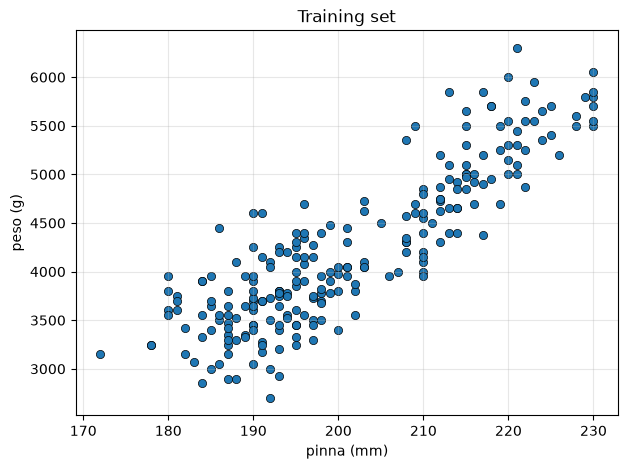

In [5]:
from sklearn.model_selection import train_test_split

X_peso = df[["pinna"]]      # doppie parentesi: un DataFrame con una sola colonna (sklearn vuole X "a tabella")
y_peso = df["peso"]         # parentesi singole: una colonna

X_peso_train, X_peso_test, y_peso_train, y_peso_test = train_test_split(
    X_peso, y_peso, test_size=0.3, random_state=0)

plt.figure(figsize=(7, 5))
plt.scatter(X_peso_train["pinna"], y_peso_train, edgecolors="k", linewidths=0.5, s=35)
plt.xlabel("pinna (mm)"); plt.ylabel("peso (g)"); plt.title("Training set")
plt.grid(alpha=0.3)
plt.show()

I punti stanno più o meno lungo una **retta**. Un modello lineare con una feature è proprio una retta:

$$\hat{y} = w \cdot x + b$$

dove $x$ è la pinna, $w$ la **pendenza** e $b$ l'**intercetta** (si scrive anche $w_0 + w_1 x$). Addestrare il modello vuol dire **trovare i valori di $w$ e $b$**.

### 2.2 Quanto è buona una retta? L'MSE
Per confrontare due rette serve un numero. Nella regressione non si contano TP e FP: si misura **quanto sono lontane** le predizioni dai valori veri. L'**errore quadratico medio** (*Mean Squared Error*) è:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2$$

Le differenze $y_i - \hat y_i$ si chiamano **residui**. Elevarle al quadrato evita che errori positivi e negativi si compensino, e pesa di più gli errori grandi.

Non serve scriverla a mano: scikit-learn ha l'MSE già pronto, nella funzione `mean_squared_error`. Proviamola su un piccolo esempio.

In [6]:
from sklearn.metrics import mean_squared_error    # l'MSE già pronto in scikit-learn

y = [3, 5, 7]
y_pred = [2, 5, 9]

print(f"{mean_squared_error(y, y_pred):.2f}")           # (1 + 0 + 4) / 3 = 1.67

1.67


### 2.3 ✏️ Esercizio: sei tu la regressione
La retta è

$$\hat{y} = w \cdot x + b$$

- $x$ è la lunghezza della pinna (in mm) e $\hat y$ il peso stimato (in g);
- $w$ è la **pendenza**: di quanti grammi cresce il peso per ogni millimetro di pinna in più;
- $b$ è l'**intercetta**: il valore di $\hat y$ quando $x = 0$.

Usa i due slider per cambiare $w$ e $b$. Nel titolo vedi la retta e il suo MSE sul training set; le linee grigie sono i **residui**. **Trova la retta con l'MSE più basso possibile** e poi esegui la cella successiva: legge i valori di $w$ e $b$ direttamente dagli slider.

💡 *Attenzione*: cambiando $w$ la retta ruota attorno al punto con $x = 0$, che è molto a sinistra del grafico (i dati vanno da circa 170 a 230 mm). Per questo, quando aumenti $w$, la retta nel grafico **si alza** oltre a diventare più ripida. Dopo ogni modifica di $w$, riporta la retta sui dati con $b$.

In [7]:
from ipywidgets import FloatSlider, Image, VBox, Layout   # ipywidgets: elementi interattivi nei notebook
from IPython.display import display
import io                                            # per salvare il grafico in memoria invece che su file

fig, ax = plt.subplots(figsize=(5, 3.1))              # una sola figura, che ridisegniamo a ogni movimento
plt.close(fig)                                       # non mostrarla qui: la mostriamo dentro `immagine`

def prova_retta(w, b):
    """Disegna la retta ŷ = w·x + b sopra i dati di training, con i residui e l'MSE."""
    x = X_peso_train["pinna"]
    pred = w * x + b                                   # una predizione per ogni pinguino, senza for
    ax.clear()                                         # cancella il disegno precedente
    ax.vlines(x, pred, y_peso_train, color="gray", alpha=0.4, linewidth=1)   # i residui
    ax.scatter(x, y_peso_train, edgecolors="k", linewidths=0.5, s=35)
    xs = np.array([170, 235])
    ax.plot(xs, w * xs + b, color="crimson", linewidth=2)
    ax.set_ylim(2000, 7000)
    ax.set_xlabel("pinna (mm)"); ax.set_ylabel("peso (g)"); ax.grid(alpha=0.3)
    segno = "+" if b >= 0 else "−"
    ax.set_title(f"ŷ = {w:.2f} · x {segno} {abs(b):.2f}      MSE = {mean_squared_error(y_peso_train, pred):.2f}")
    return fig

# continuous_update=True: il grafico si aggiorna mentre trascini lo slider
slider_w = FloatSlider(min=0, max=80, step=0.5, value=20, description="w", continuous_update=True,
                       layout=Layout(width="600px"))   # slider più lungo: più facile da regolare
slider_b = FloatSlider(min=-10000, max=5000, step=50, value=0, description="b", continuous_update=True,
                       layout=Layout(width="600px"))
immagine = Image(format="png", layout=Layout(width="600px"))   # un'immagine che sostituiamo a ogni movimento

def aggiorna(cambiamento=None):
    memoria = io.BytesIO()                             # un "file" che sta in memoria
    prova_retta(slider_w.value, slider_b.value).savefig(memoria, format="png", bbox_inches="tight")
    immagine.value = memoria.getvalue()                # al posto della vecchia immagine mette la nuova

slider_w.observe(aggiorna, names="value")              # quando cambia uno slider, richiama aggiorna
slider_b.observe(aggiorna, names="value")
display(VBox([slider_w, slider_b, immagine]))
aggiorna()

*Se gli slider non compaiono, puoi chiamare la funzione a mano, per esempio `prova_retta(40, -4000)`, e scrivere i valori migliori a mano nella cella successiva al posto di `slider_w.value` e `slider_b.value`.*

In [8]:
# ✏️ esegui questa cella quando hai trovato la tua retta migliore
mio_w = slider_w.value      # .value: il valore a cui si trova ora lo slider
mio_b = slider_b.value
print(f"La tua retta: ŷ = {mio_w:.2f} · x {mio_b:+.2f}")

La tua retta: ŷ = 20.00 · x +0.00


### 2.4 Ora lo fa l'algoritmo: `LinearRegression`

In [9]:
from sklearn.linear_model import LinearRegression

regressione = LinearRegression()             # 1) creo il modello
regressione.fit(X_peso_train, y_peso_train)  # 2) training: trova w e b

w_appreso = regressione.coef_[0]      # coef_ contiene un peso per ogni feature (qui una sola)
b_appreso = regressione.intercept_
print(f"Retta appresa: ŷ = {w_appreso:.2f} · pinna {b_appreso:+.2f}")

Retta appresa: ŷ = 51.23 · pinna -6089.73


Il modello è **interpretabile**: ogni millimetro di pinna in più vale circa 51 grammi di peso (è il valore di `w_appreso`).

Confrontiamo la tua retta con quella appresa, sul training e sul test set.

In [10]:
righe = []
for nome, w, b in [("La mia retta", mio_w, mio_b), ("LinearRegression", w_appreso, b_appreso)]:
    mse_train = mean_squared_error(y_peso_train, w * X_peso_train["pinna"] + b)
    mse_test = mean_squared_error(y_peso_test, w * X_peso_test["pinna"] + b)
    righe.append({"modello": nome, "MSE train": mse_train, "MSE test": mse_test})

pd.DataFrame(righe).round(2)

,modello,MSE train,MSE test
0,La mia retta,373976.93,351076.25
1,LinearRegression,153246.82,155816.46


📌 **Perché l'MSE è un numero così grande?** L'MSE è la media dei residui **al quadrato**, quindi si misura nell'unità del target al quadrato: qui i **grammi al quadrato** (g²). Un residuo di 400 g diventa $400^2 = 160\,000$ g², e la media di tanti quadrati così finisce nelle centinaia di migliaia.

Se il peso fosse in chilogrammi, la stessa retta avrebbe un MSE un milione di volte più piccolo: 400 g sono 0,4 kg, e $0{,}4^2 = 0{,}16$. Il modello sarebbe identico, cambierebbe solo il numero.

Quindi il valore dell'MSE, da solo, non dice se un modello è buono o no: serve un **termine di paragone**. Il più semplice è un modello che ignora la pinna e prevede **sempre il peso medio** del training set.

In [11]:
media_train = y_peso_train.mean()                          # il peso medio dei pinguini di training
sempre_media = np.full(len(y_peso_test), media_train)      # np.full: un array lungo quanto il test set, tutto uguale alla media
print(f"Prevedo sempre {media_train:.2f} g → MSE test = {mean_squared_error(y_peso_test, sempre_media):.2f}")
print(f"LinearRegression          → MSE test = {mean_squared_error(y_peso_test, regressione.predict(X_peso_test)):.2f}")

Prevedo sempre 4232.30 g → MSE test = 670791.94
LinearRegression          → MSE test = 155816.46


Usando la pinna l'MSE scende di circa **4 volte** rispetto a chi tira a indovinare con la media: la retta è utile. È così che si legge l'MSE: **confrontando modelli diversi sugli stessi dati**, come faremo nella 2.6 aggiungendo altre misure.

### 2.5 ⏩ Come trova la retta? I minimi quadrati
`LinearRegression` sceglie i valori di $w$ e $b$ che rendono l'MSE **il più piccolo possibile**: per questo il metodo si chiama **minimi quadrati**. Il nome si capisce con un disegno: il quadrato di un residuo, $(y_i - \hat y_i)^2$, è l'**area di un quadrato** di lato $|y_i - \hat y_i|$, e l'MSE è la media di queste aree.

Per vederlo usiamo pochi punti di esempio, con la stessa unità di misura sui due assi. Sui pinguini non si potrebbe: un asse è in mm e l'altro in g, e i quadrati verrebbero rettangoli.

Nell'animazione la retta ruota attorno al **punto medio** dei dati, da cui passa sempre la retta migliore. A sinistra vedi i quadrati dei residui, a destra l'MSE in funzione della pendenza $w$. Esegui la cella e premi ▶.

In [12]:
#@title 🎬 Animazione: i minimi quadrati (esegui la cella e premi ▶)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML

# pochi punti di esempio, con la stessa unità di misura sui due assi
x_es = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0])
y_es = np.array([2.0, 3.6, 2.8, 5.2, 4.4, 6.6, 6.0])

w_ottimo, b_ottimo = np.polyfit(x_es, y_es, 1)        # la retta dei minimi quadrati
x_medio, y_medio = x_es.mean(), y_es.mean()           # la retta migliore passa sempre per il punto medio

def mse_di(w):
    b = y_medio - w * x_medio                          # la retta ruota attorno al punto medio
    return np.mean((y_es - (w * x_es + b)) ** 2)

# la pendenza va da 0 a oltre l'ottimo, poi torna indietro e si ferma sull'ottimo
w_frames = np.concatenate([np.linspace(0, 1.6, 30), np.linspace(1.6, w_ottimo, 22),
                           np.full(10, w_ottimo)])
w_curva = np.linspace(-0.1, 1.7, 200)

fig, (ax_retta, ax_mse) = plt.subplots(1, 2, figsize=(10, 4.5), dpi=72)
ax_mse.plot(w_curva, [mse_di(w) for w in w_curva], color="gray")
ax_mse.axvline(w_ottimo, color="seagreen", linestyle="--", linewidth=1, label=f"minimo: w = {w_ottimo:.2f}")
punto_mse, = ax_mse.plot([], [], "o", color="crimson", markersize=9)
ax_mse.set_xlabel("pendenza w"); ax_mse.set_ylabel("MSE"); ax_mse.grid(alpha=0.3)
ax_mse.set_title("L'MSE al variare di w"); ax_mse.legend(loc="upper center")

def disegna(i):
    w = w_frames[i]
    b = y_medio - w * x_medio
    pred = w * x_es + b
    ax_retta.clear()
    for xi, yi, pi in zip(x_es, y_es, pred):
        r = yi - pi                                    # residuo
        ax_retta.add_patch(Rectangle((xi, min(yi, pi)), abs(r), abs(r),
                                     color="crimson", alpha=0.25))   # quadrato di lato |residuo|
        ax_retta.plot([xi, xi], [yi, pi], color="crimson", linewidth=1)
    ax_retta.scatter(x_es, y_es, color="steelblue", edgecolors="k", zorder=3, s=50)
    xs = np.array([0, 10])
    ax_retta.plot(xs, w * xs + b, color="k", linewidth=2)
    ax_retta.set_xlim(0, 10); ax_retta.set_ylim(-1, 9); ax_retta.set_aspect("equal")
    ax_retta.grid(alpha=0.3); ax_retta.set_xlabel("x"); ax_retta.set_ylabel("y")
    ax_retta.set_title(f"ŷ = {w:.2f}·x {'+' if b >= 0 else '−'} {abs(b):.2f}     MSE = {mse_di(w):.2f}")
    punto_mse.set_data([w], [mse_di(w)])

animazione = FuncAnimation(fig, disegna, frames=len(w_frames), interval=100)
plt.close(fig)                                         # mostriamo solo l'animazione, non la figura ferma
HTML(animazione.to_jshtml())

📌 L'MSE in funzione di $w$ è una curva con **un solo minimo**: la retta migliore è quella in cui la somma delle aree dei quadrati è più piccola. Per la regressione lineare esiste una formula che trova direttamente questo minimo, ed è quella che usa `LinearRegression`.

### 2.6 Più misure: dalla retta al piano
Con **due** feature il modello lineare diventa un **piano**:

$$\hat{y} = w_{pinna} \cdot x_{pinna} + w_{becco} \cdot x_{becco} + b$$

Al posto di un solo $w$ c'è un peso per ogni feature; $b$ è sempre l'intercetta.

Il grafico qui sotto è **interattivo**: trascinalo con il mouse per ruotarlo. Lo disegniamo con **plotly**, una libreria per grafici interattivi.

In [13]:
import plotly.graph_objects as go

X2 = df[["pinna", "becco_lunghezza"]]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y_peso, test_size=0.3, random_state=0)
regressione2 = LinearRegression().fit(X2_train, y2_train)
print(f"Pesi: pinna {regressione2.coef_[0]:.2f}, becco_lunghezza {regressione2.coef_[1]:.2f} | intercetta: {regressione2.intercept_:.2f}")

# il piano: calcolo la predizione su una griglia di valori (pinna, becco)
pp, bb = np.meshgrid(np.linspace(170, 235, 20), np.linspace(32, 60, 20))
griglia = pd.DataFrame({"pinna": pp.ravel(), "becco_lunghezza": bb.ravel()})
zz = regressione2.predict(griglia).reshape(pp.shape)

fig = go.Figure()
fig.add_trace(go.Scatter3d(x=X2_train["pinna"], y=X2_train["becco_lunghezza"], z=y2_train,
                           mode="markers", marker=dict(size=3, color="steelblue"), name="pinguini"))
fig.add_trace(go.Surface(x=pp, y=bb, z=zz, opacity=0.5, showscale=False,
                         colorscale=[[0, "crimson"], [1, "crimson"]], name="piano"))
fig.update_layout(height=550, margin=dict(l=0, r=0, t=30, b=0),
                  scene=dict(xaxis_title="pinna (mm)", yaxis_title="becco_lunghezza (mm)", zaxis_title="peso (g)"))
fig.show()

Pesi: pinna 50.28, becco_lunghezza 3.90 | intercetta: -6070.97


Il piano sale quasi solo lungo la pinna: il suo peso è 50.28 g per mm, quello del becco appena 3.90. Con la pinna già nel modello, la lunghezza del becco cambia poco la stima del peso.

E se volessimo usare anche **specie**, **isola** e **sesso**? Sono parole, ma il modello lavora solo con numeri: le categorie vanno **codificate**. Il modo più comune è il **one-hot encoding**: una colonna 0/1 per ogni valore possibile.

In [14]:
df.head()

,specie,isola,becco_lunghezza,becco_profondita,pinna,peso,sesso
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,maschio
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,femmina
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,femmina
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,femmina
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,maschio



> 🐍 `pd.get_dummies` crea le colonne 0/1. Con `drop_first=True` toglie la prima di ogni gruppo, perché è ridondante: se un pinguino non è né Chinstrap né Gentoo, è per forza Adelie.

In [15]:
X_tutte = pd.get_dummies(df.drop(columns=["peso"]),            # tutte le colonne tranne il target
                         columns=["specie", "isola", "sesso"], drop_first=True, dtype=int)
X_tutte.head()

,becco_lunghezza,becco_profondita,pinna,specie_Chinstrap,specie_Gentoo,isola_Dream,isola_Torgersen,sesso_maschio
0,39.1,18.7,181.0,0,0,0,1,1
1,39.5,17.4,186.0,0,0,0,1,0
2,40.3,18.0,195.0,0,0,0,1,0
4,36.7,19.3,193.0,0,0,0,1,0
5,39.3,20.6,190.0,0,0,0,1,1


In [16]:
insiemi_di_feature = {
    "solo pinna": ["pinna"],
    "pinna + becco_lunghezza": ["pinna", "becco_lunghezza"],
    "tutte (con le categorie)": list(X_tutte.columns),
}

righe = []
for nome, colonne in insiemi_di_feature.items():
    Xa, Xb, ya, yb = train_test_split(X_tutte[colonne], y_peso, test_size=0.3, random_state=0)  # stessa divisione di prima
    modello = LinearRegression().fit(Xa, ya)
    righe.append({"feature": nome, "MSE test": mean_squared_error(yb, modello.predict(Xb))})
pd.DataFrame(righe).round(2)

,feature,MSE test
0,solo pinna,155816.46
1,pinna + becco_lunghezza,155230.77
2,tutte (con le categorie),81692.13


> 🤔 Aggiungere il becco non serve quasi a niente, aggiungere specie e sesso invece migliora molto. Perché? Guarda i pesi del modello completo: quanto pesa in più, a parità di misure, un maschio? E un Gentoo?


In [17]:
# qui non valutiamo il modello, leggiamo i suoi pesi: lo addestriamo su tutti i pinguini
modello_completo = LinearRegression().fit(X_tutte, y_peso)
pd.Series(modello_completo.coef_, index=X_tutte.columns).round(2)

becco_lunghezza      18.19
becco_profondita     67.58
pinna                16.24
specie_Chinstrap   -260.31
specie_Gentoo       987.76
isola_Dream         -13.10
isola_Torgersen     -48.06
sesso_maschio       387.22
dtype: float64

<details>
<summary><b>💡 Risposta</b> (clicca per aprire, ma prima prova a rispondere!)</summary>

A parità di tutte le altre colonne, un **maschio** pesa circa 387 g in più di una femmina, e un **Gentoo** circa 988 g in più di un Adelie (Adelie è la specie tolta da `drop_first=True`, quella di riferimento). Sono informazioni che le misure non contengono: due pinguini con la stessa pinna possono pesare molto diversamente se sono di sesso o di specie diversi.

</details>

### 2.7 Un albero al posto della retta
Stesso problema, **nuovo modello**: stimiamo ancora il peso dalla pinna, con la stessa divisione train/test, ma al posto della retta usiamo un **albero**.

Un albero può fare anche **regressione**: ogni foglia predice la **media** dei pesi dei pinguini che ci arrivano, e l'impurità di un nodo è la sua **varianza**, cioè l'MSE rispetto alla media.

Come gli alberi di classificazione dell'Esercitazione 1, un albero senza limiti continua a dividere finché insegue i singoli pinguini del training set: è l'**overfitting**. Il modo più semplice per fermarlo è limitare la profondità con `max_depth` (ci sono anche altri iperparametri, per esempio `min_samples_leaf`: quanti pinguini devono restare almeno in ogni foglia).

Usa lo slider per cambiare `max_depth`: la linea rossa sono i gradini dell'albero, quella tratteggiata la retta della 2.4, le zone gialle sono fuori dal range dei dati di training. Nel titolo vedi l'MSE dell'albero sul training e sul test set. Da `max_depth = 9` in su l'albero è già **senza limiti**: più profondo di così non riesce a dividere.

In [18]:
from sklearn.tree import DecisionTreeRegressor
from ipywidgets import IntSlider      # come FloatSlider, ma solo con numeri interi

mse_retta = mean_squared_error(y_peso_test, regressione.predict(X_peso_test))   # la retta della 2.4, sul test set
pinne = pd.DataFrame({"pinna": np.linspace(150, 260, 500)})   # anche FUORI dal range dei dati (172-231 mm)

fig_albero, ax_albero = plt.subplots(figsize=(6, 3.6))
plt.close(fig_albero)

def prova_albero(profondita):
    """Addestra un albero di regressione con max_depth=profondita e lo disegna insieme alla retta."""
    albero = DecisionTreeRegressor(max_depth=profondita, random_state=0).fit(X_peso_train, y_peso_train)
    mse_tr = mean_squared_error(y_peso_train, albero.predict(X_peso_train))
    mse_te = mean_squared_error(y_peso_test, albero.predict(X_peso_test))
    ax_albero.clear()
    ax_albero.axvspan(150, X_peso["pinna"].min(), color="gold", alpha=0.15)     # zone senza dati di training
    ax_albero.axvspan(X_peso["pinna"].max(), 260, color="gold", alpha=0.15)
    ax_albero.scatter(X_peso_train["pinna"], y_peso_train, color="lightgray", edgecolors="k", linewidths=0.4, s=20)
    ax_albero.plot(pinne["pinna"], regressione.predict(pinne), color="k", linestyle="--",
                   label=f"retta (MSE test {mse_retta:.2f})")
    ax_albero.plot(pinne["pinna"], albero.predict(pinne), color="crimson", linewidth=2, label="albero")
    ax_albero.set_xlim(150, 260); ax_albero.set_ylim(1500, 7500)
    ax_albero.set_xlabel("pinna (mm)"); ax_albero.set_ylabel("peso (g)"); ax_albero.grid(alpha=0.3)
    ax_albero.legend(fontsize=8, loc="upper left")
    ax_albero.set_title(f"max_depth = {profondita}: {albero.get_n_leaves()} foglie\n"
                        f"MSE training {mse_tr:.2f} · MSE test {mse_te:.2f}", fontsize=10)
    return fig_albero

slider_prof = IntSlider(min=1, max=10, step=1, value=1, description="max_depth",
                        continuous_update=True, layout=Layout(width="550px"))
immagine_prof = Image(format="png", layout=Layout(width="550px"))

def aggiorna_prof(cambiamento=None):
    memoria = io.BytesIO()
    prova_albero(slider_prof.value).savefig(memoria, format="png", bbox_inches="tight")
    immagine_prof.value = memoria.getvalue()

slider_prof.observe(aggiorna_prof, names="value")
display(VBox([slider_prof, immagine_prof]))
aggiorna_prof()

*Se lo slider non compare, puoi chiamare la funzione a mano, per esempio `prova_albero(3)`.*

> 🤔 Cosa succede all'MSE di **training** aumentando la profondità? E a quello di **test**? Con quale profondità l'MSE di test è più basso?

<details>
<summary><b>💡 Risposta</b> (clicca per aprire, ma prima prova a rispondere!)</summary>

L'MSE di training **scende sempre**: da 218867.88 con profondità 1 a 108857.71 con profondità 10. Più l'albero è profondo, più si adatta ai pinguini che ha visto.

L'MSE di test invece scende fino a profondità 3 (147642.35, un po' meglio della retta, 155816.46) e poi **risale**, fino a 178079.01 con l'albero senza limiti, **peggio** della retta: l'albero sta imparando i dettagli del training set che non valgono per pinguini nuovi. È l'overfitting.

</details>

Attenzione: qui guardiamo il test set solo per **osservare** l'overfitting. Per **scegliere** davvero la profondità non si può usare il test set, altrimenti non avremmo più un modo onesto di valutare il modello alla fine: servirebbe un insieme di **validazione** separato. Come si fa lo vediamo nella Parte 3.

📌 **L'albero non estrapola.** Predice una **funzione costante a tratti** (a gradini): nelle zone gialle, fuori dal range dei dati di training, resta fermo sull'ultimo gradino, mentre la retta continua a crescere. Chi ha ragione dipende dal problema, ma è un limite da conoscere, soprattutto con trend e serie temporali.

### 2.8 ⏩ L'errore irriducibile
Nello slider della 2.7, anche con `max_depth = 10` l'MSE di training resta 108857.71, non 0. Perché l'albero non riesce a seguire tutti i punti? Guarda i pinguini del dataset con la pinna di esattamente 190 mm:

In [19]:
pinna_190 = df[df["pinna"] == 190][["specie", "sesso", "peso"]].sort_values("peso")   # .sort_values: ordina per peso
print(f"{len(pinna_190)} pinguini con la pinna di 190 mm, da {pinna_190['peso'].min():.0f} a {pinna_190['peso'].max():.0f} g")
pinna_190

21 pinguini con la pinna di 190 mm, da 3050 a 4600 g


,specie,sesso,peso
68,Adelie,femmina,3050.0
130,Adelie,femmina,3325.0
198,Chinstrap,femmina,3400.0
52,Adelie,femmina,3450.0
170,Chinstrap,femmina,3450.0
48,Adelie,femmina,3450.0
166,Chinstrap,femmina,3575.0
89,Adelie,femmina,3600.0
70,Adelie,femmina,3600.0
5,Adelie,maschio,3650.0


Hanno tutti la stessa pinna, ma pesi diversi. **Nessun modello** che usa solo la pinna può distinguerli: a tutti darà la stessa predizione. Questa parte di errore è **irriducibile** con questa feature, e nessuna profondità la elimina.

Per ridurla servono **altre feature**: nella 2.6, aggiungendo tutte le altre colonne (comprese specie e sesso), l'MSE di test della regressione lineare scendeva da 155816.46 a 81692.13.

### 2.9 ⏩ ✏️ Sei tu l'albero: come sceglie la prima domanda
Come fa l'albero a decidere dove mettere i gradini? A ogni nodo:
1. prova **tutte le soglie** possibili sulla feature;
2. per ogni soglia divide i pinguini in due gruppi: **sinistra** (pinna $\leq$ soglia) e **destra** (pinna $>$ soglia);
3. in ciascun gruppo predice la **media** del peso;
4. sceglie la soglia che rende più piccolo l'**MSE pesato** dei due gruppi:

$$MSE_{pesato} = \frac{n_{sinistra}}{n} \cdot MSE_{sinistra} + \frac{n_{destra}}{n} \cdot MSE_{destra}$$

L'MSE di un gruppo è quello che si ottiene predicendo per tutti i pinguini del gruppo la sua media. I pesi $\frac{n_{sinistra}}{n}$ e $\frac{n_{destra}}{n}$ fanno contare di più il gruppo più numeroso.

Le due funzioni qui sotto fanno proprio questo calcolo sul training set della 2.7.

> 🐍 `y_peso_train[pinna_train <= soglia]` è un **filtro**: `pinna_train <= soglia` è una colonna di `True`/`False`, e tra parentesi quadre tiene solo i pesi dei pinguini in cui vale `True`.

In [20]:
pinna_train = X_peso_train["pinna"]

def mse_gruppo(y_gruppo):
    """MSE di un gruppo quando a tutti i suoi pinguini si predice la media del gruppo."""
    if len(y_gruppo) == 0:                       # gruppo vuoto: non contribuisce all'errore
        return 0.0
    return mean_squared_error(y_gruppo, np.full(len(y_gruppo), y_gruppo.mean()))

def mse_pesato(soglia):
    """MSE pesato dei due gruppi che si ottengono con la domanda "pinna <= soglia?"."""
    sinistra = y_peso_train[pinna_train <= soglia]     # i pesi dei pinguini con la pinna corta
    destra = y_peso_train[pinna_train > soglia]        # i pesi dei pinguini con la pinna lunga
    n = len(y_peso_train)
    return len(sinistra) / n * mse_gruppo(sinistra) + len(destra) / n * mse_gruppo(destra)

print(f"MSE pesato con soglia 200: {mse_pesato(200):.2f}")

MSE pesato con soglia 200: 257512.63


Usa lo slider per spostare la soglia. La linea tratteggiata è la soglia; i due segmenti rossi sono le **medie** dei due gruppi, cioè quello che l'albero predice a sinistra e a destra. Nel titolo vedi l'MSE pesato. **Trova la soglia con l'MSE pesato più basso** e scrivila nella cella successiva.

In [21]:
fig_soglia, ax_soglia = plt.subplots(figsize=(6, 3.75))   # una figura separata da quella della 2.3
plt.close(fig_soglia)

def prova_soglia(soglia):
    """Disegna i pinguini di training, la soglia e la media dei due gruppi."""
    media_sinistra = y_peso_train[pinna_train <= soglia].mean()
    media_destra = y_peso_train[pinna_train > soglia].mean()
    ax_soglia.clear()
    ax_soglia.scatter(pinna_train, y_peso_train, color="lightgray", edgecolors="k", linewidths=0.4, s=25)
    ax_soglia.axvline(soglia, color="k", linestyle="--", linewidth=1.5)               # la soglia
    ax_soglia.hlines(media_sinistra, 170, soglia, color="crimson", linewidth=3)        # media a sinistra
    ax_soglia.hlines(media_destra, soglia, 233, color="crimson", linewidth=3)          # media a destra
    ax_soglia.set_xlim(170, 233); ax_soglia.set_ylim(2000, 7000)
    ax_soglia.set_xlabel("pinna (mm)"); ax_soglia.set_ylabel("peso (g)"); ax_soglia.grid(alpha=0.3)
    ax_soglia.set_title(f"soglia = {soglia:.1f} mm      MSE pesato = {mse_pesato(soglia):.2f}")
    return fig_soglia

slider_soglia = FloatSlider(min=172, max=231, step=0.5, value=200, description="soglia",
                            continuous_update=True, layout=Layout(width="600px"))
immagine_soglia = Image(format="png", layout=Layout(width="600px"))

def aggiorna_soglia(cambiamento=None):
    memoria = io.BytesIO()
    prova_soglia(slider_soglia.value).savefig(memoria, format="png", bbox_inches="tight")
    immagine_soglia.value = memoria.getvalue()

slider_soglia.observe(aggiorna_soglia, names="value")
display(VBox([slider_soglia, immagine_soglia]))
aggiorna_soglia()

*Se lo slider non compare, puoi chiamare la funzione a mano, per esempio `prova_soglia(200)`.*

In [22]:
# ✏️ scrivi qui la soglia migliore che hai trovato
mia_soglia = 200.0

<details>
<summary><b>💡 Soluzione</b> (clicca per aprire, ma prima prova da solo!)</summary>

```python
mia_soglia = 207.5
```

Con questa soglia l'MSE pesato scende a 218867.88. Spostandola anche di poco, a destra o a sinistra, risale.

</details>

Ora facciamo fare la ricerca al computer, come fa l'albero: proviamo **tutte** le soglie candidate, cioè i punti medi tra due valori consecutivi della pinna nel training set.

> 🐍 `np.unique(x)` restituisce i valori distinti di `x`, già ordinati. `valori[:-1]` sono tutti tranne l'ultimo, `valori[1:]` tutti tranne il primo: sommandoli e dividendo per 2 si ottengono i punti medi tra valori consecutivi. `np.argmin(lista)` dice in quale **posizione** si trova il valore più piccolo.

MSE della radice (prima di dividere): 636878.10
Soglia migliore: 207.50 mm  →  MSE pesato 218867.88
La tua soglia:   200.00 mm  →  MSE pesato 257512.63


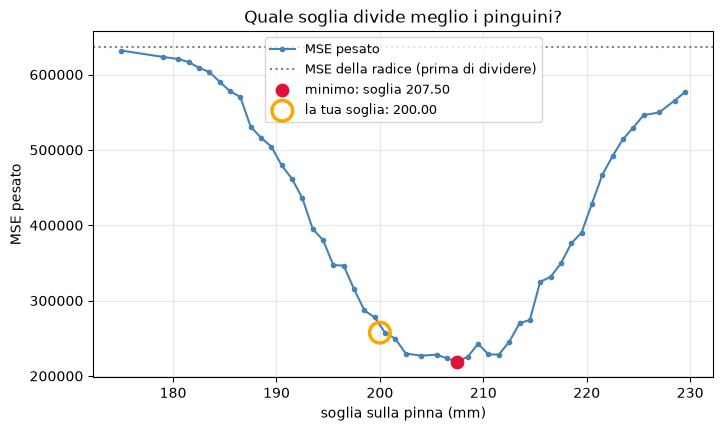

In [23]:
valori = np.unique(pinna_train)                      # le lunghezze di pinna distinte, in ordine
soglie = (valori[:-1] + valori[1:]) / 2              # i punti medi tra valori consecutivi
errori = [mse_pesato(s) for s in soglie]             # l'MSE pesato di ogni soglia candidata
migliore = soglie[np.argmin(errori)]                 # la soglia con l'MSE pesato più basso
mse_radice = mse_gruppo(y_peso_train)                # l'MSE prima di dividere: tutti nello stesso gruppo

print(f"MSE della radice (prima di dividere): {mse_radice:.2f}")
print(f"Soglia migliore: {migliore:.2f} mm  →  MSE pesato {min(errori):.2f}")
print(f"La tua soglia:   {mia_soglia:.2f} mm  →  MSE pesato {mse_pesato(mia_soglia):.2f}")

plt.figure(figsize=(8, 4.5))
plt.plot(soglie, errori, marker=".", color="steelblue", label="MSE pesato")
plt.axhline(mse_radice, color="gray", linestyle=":", label="MSE della radice (prima di dividere)")
plt.scatter([migliore], [min(errori)], color="crimson", s=80, zorder=3, label=f"minimo: soglia {migliore:.2f}")
plt.scatter([mia_soglia], [mse_pesato(mia_soglia)], facecolors="none", edgecolors="orange", linewidths=2.5, s=220, zorder=4,
            label=f"la tua soglia: {mia_soglia:.2f}")
plt.xlabel("soglia sulla pinna (mm)"); plt.ylabel("MSE pesato"); plt.grid(alpha=0.3)
plt.legend(fontsize=9); plt.title("Quale soglia divide meglio i pinguini?")
plt.show()

Controlliamo che scikit-learn faccia la stessa scelta. Un albero con `max_depth=1` fa **una sola domanda**: la prima.

Soglia scelta da scikit-learn: 207.50 mm


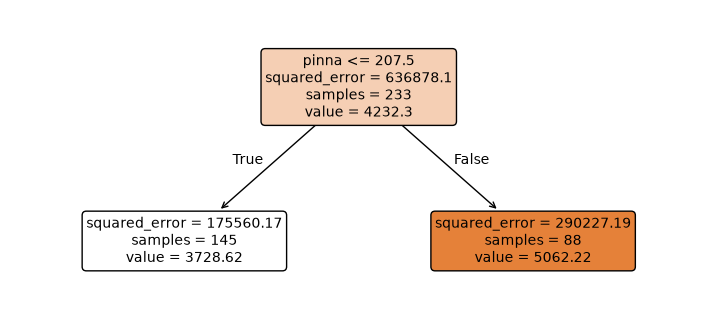

In [24]:
from sklearn.tree import plot_tree

albero_radice = DecisionTreeRegressor(max_depth=1, random_state=0).fit(X_peso_train, y_peso_train)
print(f"Soglia scelta da scikit-learn: {albero_radice.tree_.threshold[0]:.2f} mm")   # tree_: la struttura interna

plt.figure(figsize=(9, 4))
plot_tree(albero_radice, feature_names=["pinna"], filled=True, rounded=True, precision=2, fontsize=10)
plt.show()

**Come si legge un nodo.** Ogni riquadro è un nodo, cioè un gruppo di pinguini del training set:

| Voce | Significato | Nella radice |
|---|---|---|
| `pinna <= 207.5` | la **domanda** del nodo: c'è solo nei nodi che si dividono, non nelle foglie | soglia 207.5 mm |
| `squared_error` | l'**MSE del gruppo**: quanto i pesi si allontanano dalla loro media (è `mse_gruppo`, definita sopra) | 636878.1 |
| `samples` | quanti **pinguini** del training set sono finiti nel nodo | 233 |
| `value` | la **media dei pesi** del gruppo, in grammi: è la predizione dell'albero per chi finisce in quel nodo | 4232.3 |

- Le frecce: a **sinistra** (`True`) vanno i pinguini per cui la risposta alla domanda è sì (pinna ≤ 207.5 mm), a **destra** (`False`) gli altri.
- I riquadri senza domanda sono le **foglie**: 145 pinguini con media 3728.62 g a sinistra, 88 con media 5062.22 g a destra.
- Il **colore** (`filled=True`) segue `value`: si va dal bianco (il peso previsto più basso) all'arancione intenso (il più alto).

Le foglie collegano il disegno ai conti di prima: la media pesata dei loro `squared_error`, (145 × 175560.17 + 88 × 290227.19) / 233 = 218867.88, è proprio il minimo dell'MSE pesato trovato dalla ricerca su tutte le soglie.

📌 La soglia è la stessa: 207.50 mm. L'albero completo **ripete la stessa ricerca** dentro ciascuno dei due gruppi, e poi dentro i gruppi che ne escono, finché non scatta un **criterio di stop**, come `max_depth` nella 2.7.

### 2.10 Il contrario: la regressione per classificare
Nella 2.7 abbiamo usato un albero per fare **regressione**. Si può fare anche il contrario: usare la regressione lineare per **classificare**. Per vederlo cambiamo problema.

> 📋 **Il problema: che specie è?**
> - **Dati:** i pinguini Adelie e Chinstrap, le due specie più simili tra loro
> - **Target `y`:** `specie`, un'**etichetta**: Adelie o Chinstrap
> - **Feature `X`:** `becco_lunghezza` e `becco_profondita`
> - **Tipo di problema:** **classificazione binaria**
> - **Come lo valutiamo:** accuracy

> 🤔 **Le feature utili dipendono dalla domanda.** Nella 2.6, aggiungere `becco_lunghezza` alla pinna non migliorava quasi per niente la stima del peso. Vuol dire che il becco è una misura poco utile? Guarda le misure medie delle due specie qui sotto: quale misura serve per distinguere un Adelie da un Chinstrap? E la pinna, la migliore per il peso, serve anche qui?

> 🐍 `.groupby("specie")` divide la tabella in gruppi, uno per specie; `.mean()` calcola la media di ogni colonna dentro ciascun gruppo.

In [25]:
due_specie = df[df["specie"].isin(["Adelie", "Chinstrap"])]     # .isin: tiene solo le righe con quei valori
misure = ["becco_lunghezza", "becco_profondita", "pinna", "peso"]
due_specie.groupby("specie")[misure].mean().round(2)              # la media di ogni misura, specie per specie

,becco_lunghezza,becco_profondita,pinna,peso
specie,,,,
Adelie,38.82,18.35,190.10,3706.16
Chinstrap,48.83,18.42,195.82,3733.09


<details>
<summary><b>💡 Risposta</b> (clicca per aprire, ma prima prova a rispondere!)</summary>

Per distinguere le due specie la misura decisiva è **`becco_lunghezza`**: in media il becco dei Chinstrap è circa 1 cm più lungo di quello degli Adelie. Profondità del becco, pinna e peso invece sono quasi uguali nelle due specie, quindi da sole servono a poco. La pinna, la feature migliore per stimare il peso, qui è tra le meno utili.

Quindi il becco non è una misura poco utile: aggiunto alla pinna cambiava poco la stima del **peso**, ma per distinguere le **specie** è la misura decisiva.

📌 Una feature non è importante in assoluto: dipende dalla **domanda** a cui vogliamo rispondere e dalle **altre feature** già presenti nel modello.

</details>

Il trucco è **trasformare le classi in numeri** (Chinstrap = **+1**, Adelie = **−1**), addestrare una regressione e poi classificare con una **soglia**: se $\hat y \geq 0$ dico Chinstrap, altrimenti Adelie.

Attenzione: il **problema** resta di classificazione, perché la risposta è una specie. È solo il **modello** che prendiamo in prestito dalla regressione.

In [26]:
X_due = due_specie[["becco_lunghezza", "becco_profondita"]]
y_due = due_specie["specie"]

X_due_train, X_due_test, y_due_train, y_due_test = train_test_split(
    X_due, y_due, test_size=0.3, random_state=0, stratify=y_due)

# np.where(condizione, valore_se_vero, valore_se_falso) lavora elemento per elemento
y_numerico = np.where(y_due_train == "Chinstrap", 1, -1)

regressione_specie = LinearRegression().fit(X_due_train, y_numerico)

# cosa restituisce la regressione? numeri "continui", non classi!
uscite = regressione_specie.predict(X_due_test.head(8))
pd.DataFrame({"uscita della regressione": uscite.round(2),
              "classe con soglia 0": np.where(uscite >= 0, "Chinstrap", "Adelie"),
              "classe vera": y_due_test.head(8).to_numpy()})

,uscita della regressione,classe con soglia 0,classe vera
0,0.43,Chinstrap,Chinstrap
1,-0.46,Adelie,Adelie
2,-0.01,Adelie,Chinstrap
3,-0.67,Adelie,Adelie
4,1.00,Chinstrap,Chinstrap
5,-1.01,Adelie,Adelie
6,-0.69,Adelie,Adelie
7,0.78,Chinstrap,Chinstrap


In [27]:
from sklearn.metrics import accuracy_score

def classificatore_lineare(X):
    """Regressione + soglia: restituisce un'etichetta per ogni riga di X."""
    return np.where(regressione_specie.predict(X) >= 0, "Chinstrap", "Adelie")

print(f"Accuracy sul test set: {accuracy_score(y_due_test, classificatore_lineare(X_due_test)):.2f}")

Accuracy sul test set: 0.95


La regressione calcola un **piano** sopra il grafico: a ogni coppia di misure del becco associa un valore $\hat y$ (a sinistra, il colore). La soglia $\hat y = 0$ taglia il piano lungo una **retta**: quella retta è la **frontiera decisionale** (a destra), che separa la zona in cui il modello dice Chinstrap da quella in cui dice Adelie.

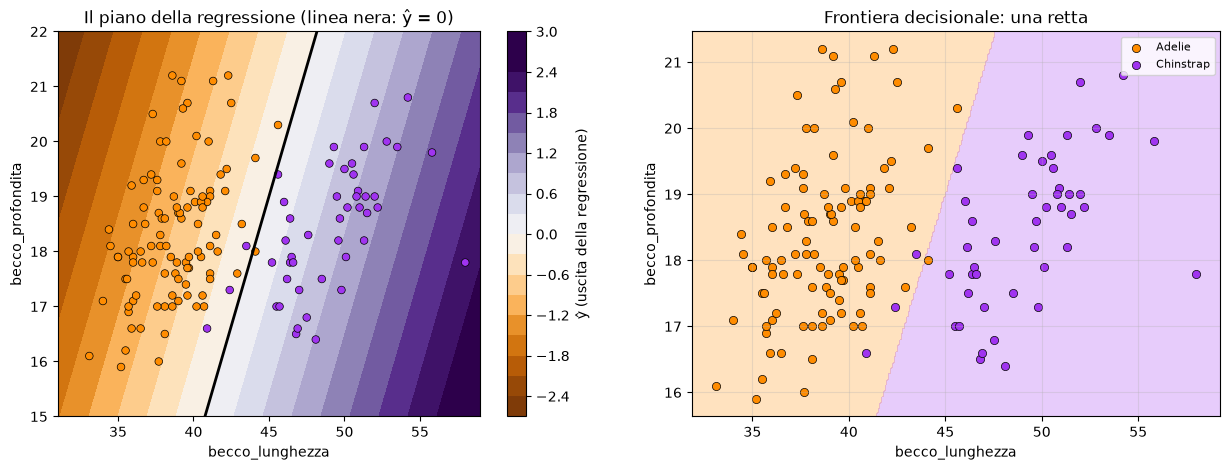

In [28]:
fig, assi = plt.subplots(1, 2, figsize=(15, 5))

# a sinistra: il valore continuo della regressione su una griglia di punti
ll, pp = np.meshgrid(np.linspace(31, 59, 200), np.linspace(15, 22, 200))
griglia = pd.DataFrame({"becco_lunghezza": ll.ravel(), "becco_profondita": pp.ravel()})
valori = regressione_specie.predict(griglia).reshape(ll.shape)
mappa = assi[0].contourf(ll, pp, valori, levels=20, cmap="PuOr", vmin=-2.5, vmax=2.5)
assi[0].contour(ll, pp, valori, levels=[0], colors="k", linewidths=2)    # la linea dove ŷ = 0
fig.colorbar(mappa, ax=assi[0], label="ŷ (uscita della regressione)")
assi[0].scatter(X_due_train["becco_lunghezza"], X_due_train["becco_profondita"],
                c=[COLORI[s] for s in y_due_train], edgecolors="k", linewidths=0.5, s=30)
assi[0].set_xlabel("becco_lunghezza"); assi[0].set_ylabel("becco_profondita")
assi[0].set_title("Il piano della regressione (linea nera: ŷ = 0)")

# a destra: le due regioni di decisione
disegna_frontiera(classificatore_lineare, X_due_train, y_due_train, "Frontiera decisionale: una retta", ax=assi[1])
plt.show()

📌 Con un modello lineare la frontiera decisionale è sempre una **retta** (con tre feature un piano, con più feature un iperpiano).

📌 Regressione e classificazione sono due tipi di **problema**, non di modello: un albero può fare regressione (2.7) e una regressione, con una soglia, può classificare. Il trucco della soglia però funziona solo con **due** classi: con tre servirebbe un modello per classe, oppure un modello pensato apposta per la classificazione, come la *regressione logistica*. Gli alberi invece gestiscono direttamente anche il caso multiclasse.

---
# Parte 3 — Classificare il sesso: gli iperparametri e come sceglierli

Nella 2.7 abbiamo visto che per **scegliere** la profondità di un albero non si può usare il test set. Da qui alla fine vediamo come si fa, su un problema di classificazione.

### 3.1 Il problema e il primo albero
Usiamo gli stessi pinguini della Parte 1 (la tabella `df`), ma con un'altra domanda.

> 📋 **Il problema: è maschio o femmina?**
> - **Dati:** i 333 pinguini della Parte 1
> - **Target `y`:** `sesso`: maschio o femmina
> - **Feature `X`:** `becco_lunghezza` e `becco_profondita` (con due feature possiamo disegnare la frontiera)
> - **Tipo di problema:** **classificazione binaria**
> - **Come lo valutiamo:** accuracy, stimata con la cross-validation sul training set; il test set solo alla fine

Training: 233 | test: 100


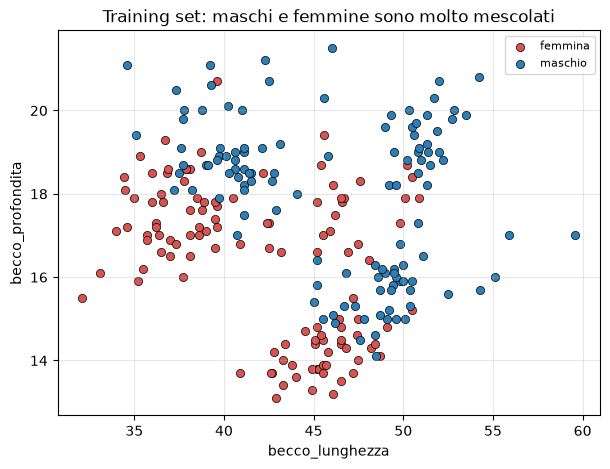

In [29]:
X = df[["becco_lunghezza", "becco_profondita"]]
y = df["sesso"]

# stratify=y: training e test con la stessa proporzione di maschi e femmine
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

print("Training:", len(X_train), "| test:", len(X_test))
mostra_punti(X_train, y_train, "Training set: maschi e femmine sono molto mescolati")

🔒 **Da qui in avanti il test set resta chiuso.** Lo apriremo una volta sola, alla fine della Parte 4, quando avremo scelto l'albero.

Cominciamo con un albero senza limiti, guardando solo il training set:

Profondità: 11 | foglie: 47
Accuracy sul training set: 1.00


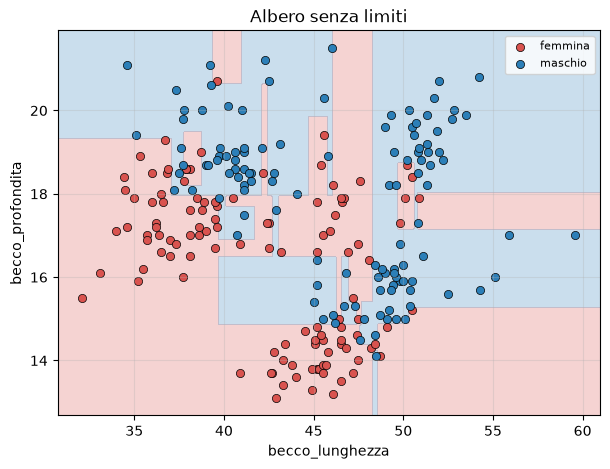

In [30]:
from sklearn.tree import DecisionTreeClassifier

albero_libero = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("Profondità:", albero_libero.get_depth(), "| foglie:", albero_libero.get_n_leaves())
print(f"Accuracy sul training set: {accuracy_score(y_train, albero_libero.predict(X_train)):.2f}")
disegna_frontiera(albero_libero, X_train, y_train, "Albero senza limiti")

Accuracy di training **1.00**, con una frontiera piena di **isolette** costruite attorno a singoli pinguini: l'albero ha imparato a memoria il training set. Quanto andrà su pinguini nuovi non lo sappiamo ancora, e non possiamo chiederlo al test set. Prima vediamo quali "freni" possiamo mettere all'albero.

### 3.2 Cinque modi per fermare un albero
Oltre a `max_depth`, `DecisionTreeClassifier` ha altri iperparametri che limitano la crescita: `min_samples_leaf` (pinguini minimi in ogni foglia), `max_leaf_nodes` (foglie massime), `min_impurity_decrease` (divide un nodo solo se l'impurità scende almeno di tanto) e `ccp_alpha` (il pruning, vedi 3.3). Vediamoli all'opera.

> 🐍 `DecisionTreeClassifier(**parametri)`: i due asterischi "spacchettano" un dizionario in argomenti. Se `parametri = {"max_depth": 3}`, la chiamata equivale a `DecisionTreeClassifier(max_depth=3)`. Ci servirà per provare tante configurazioni con lo stesso codice.

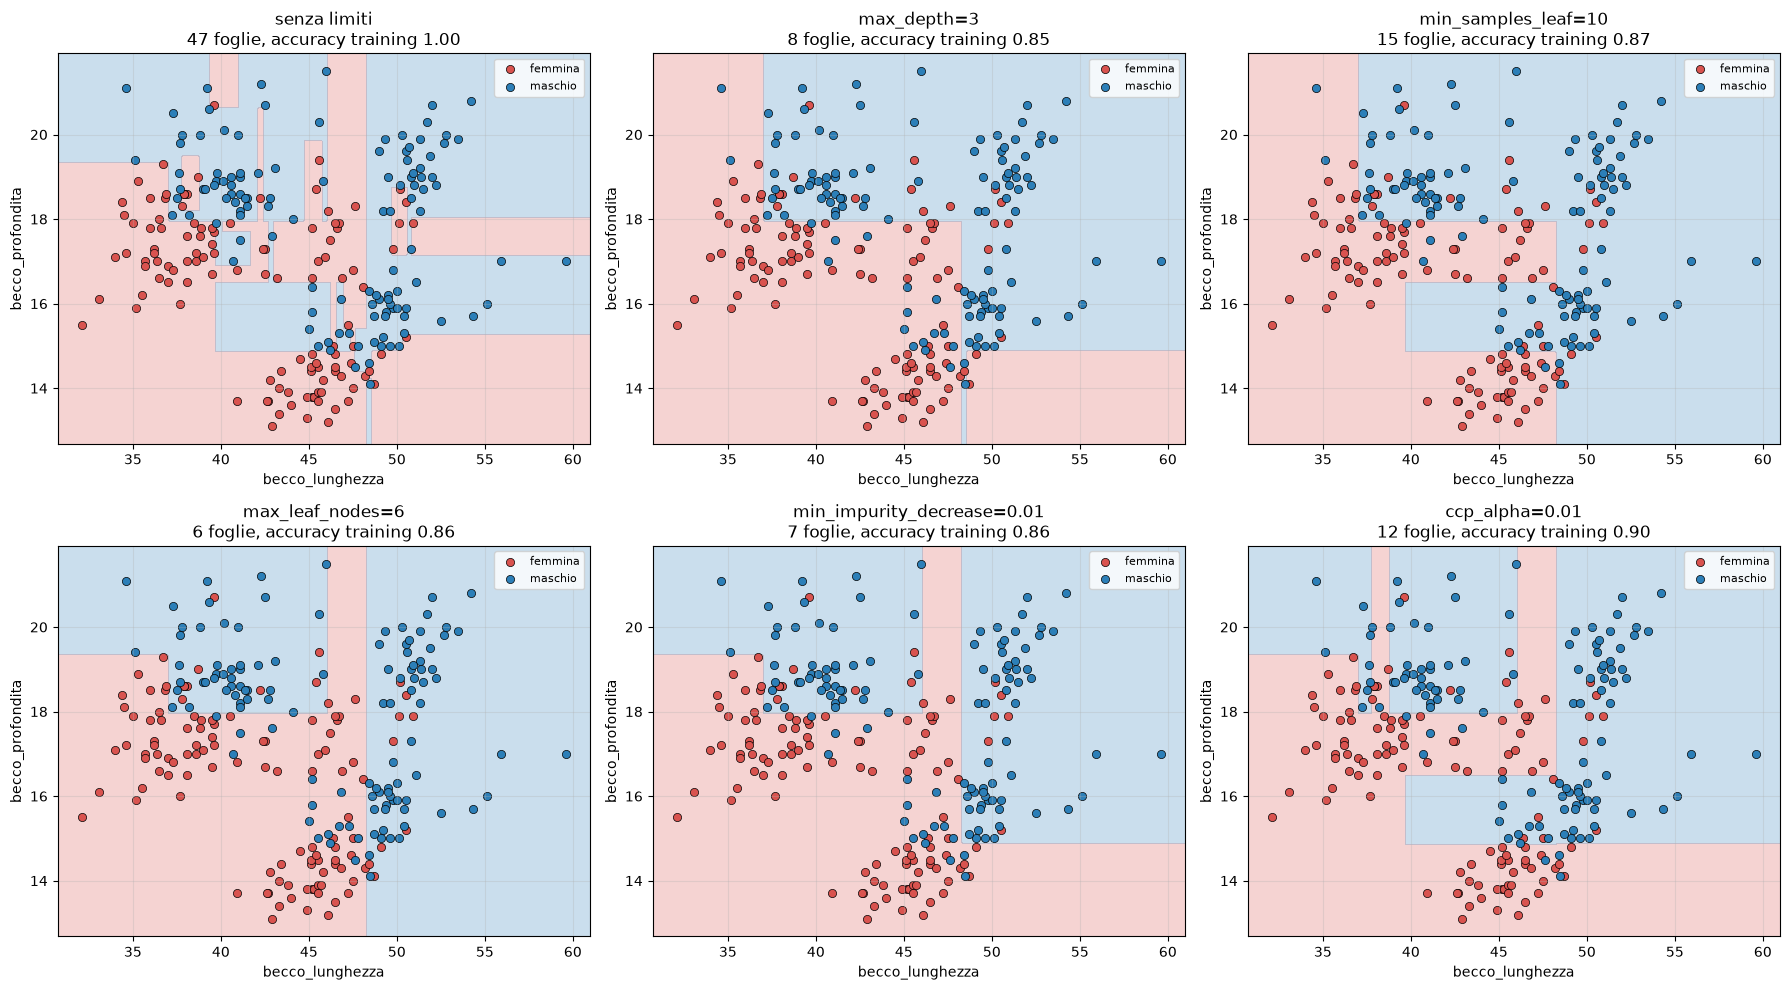

In [31]:
configurazioni = {                          # nome da mostrare → dizionario di iperparametri
    "senza limiti": {},
    "max_depth=3": {"max_depth": 3},
    "min_samples_leaf=10": {"min_samples_leaf": 10},
    "max_leaf_nodes=6": {"max_leaf_nodes": 6},
    "min_impurity_decrease=0.01": {"min_impurity_decrease": 0.01},
    "ccp_alpha=0.01": {"ccp_alpha": 0.01},
}

fig, assi = plt.subplots(2, 3, figsize=(18, 10))
# .ravel(): da matrice 2x3 a lista di 6 grafici; .items(): coppie (chiave, valore) del dizionario
for ax, (nome, parametri) in zip(assi.ravel(), configurazioni.items()):
    modello = DecisionTreeClassifier(random_state=0, **parametri).fit(X_train, y_train)
    acc = accuracy_score(y_train, modello.predict(X_train))
    disegna_frontiera(modello, X_train, y_train,
                      f"{nome}\n{modello.get_n_leaves()} foglie, accuracy training {acc:.2f}", ax=ax)
plt.tight_layout()
plt.show()

📌 Tutti fanno la stessa cosa in modi diversi: **meno foglie**, frontiera **più semplice**, accuracy di training **più bassa**. Quale sia il valore migliore non si vede da qui: lo decide la validazione (dalla 3.4 in poi).

### 3.3 ⏩ Il pruning
Ci sono due strade per avere un albero più piccolo:
- **pre-pruning**: si **ferma la crescita** in anticipo (`max_depth`, `min_samples_leaf`, `max_leaf_nodes`, `min_impurity_decrease`);
- **post-pruning**: si fa crescere l'albero **completo** e poi si **potano** i rami che servono poco. In scikit-learn si regola con `ccp_alpha`.

**Che cosa fa `ccp_alpha`.** Pensalo come il **prezzo di ogni foglia**. Per ogni ramo dell'albero completo, scikit-learn guarda due cose:
- quanto quel ramo **abbassa l'impurità** sul training set (quanto rende le foglie più "pure", cioè con una sola classe);
- quante **foglie in più** costa rispetto a sostituirlo con una foglia sola.

Se il miglioramento per ogni foglia in più è **minore di `ccp_alpha`**, il ramo "è troppo costoso" e viene tagliato: al suo posto resta una foglia sola. Con `ccp_alpha = 0` le foglie non costano niente e l'albero resta completo; più `ccp_alpha` è grande, più rami vengono tagliati.

Quali valori provare? Non serve indovinarli: `cost_complexity_pruning_path` restituisce proprio i valori di `ccp_alpha` in cui un ramo diventa "troppo costoso", cioè quelli in cui l'albero potato **cambia**. Tra due valori consecutivi l'albero resta lo stesso.

Quanti valori di ccp_alpha: 25
I primi cinque: [0.     0.0029 0.0029 0.0032 0.0032]


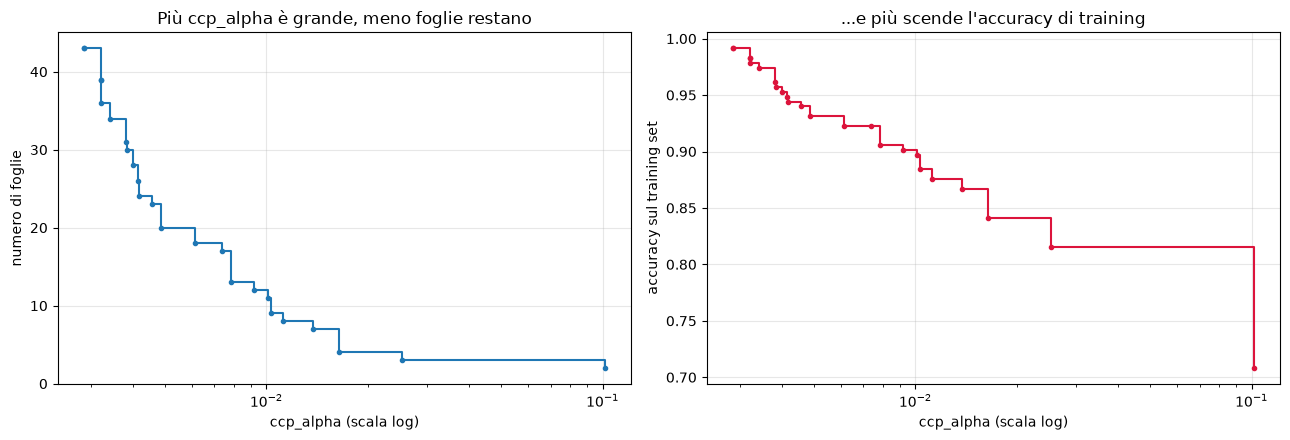

In [32]:
# calcola il "percorso di potatura" dell'albero completo sul training set
percorso = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_train, y_train)
valori_alpha = percorso.ccp_alphas[:-1]   # l'ultimo valore pota tutto e lascia solo la radice: lo escludiamo

print("Quanti valori di ccp_alpha:", len(valori_alpha))
print("I primi cinque:", valori_alpha[:5].round(4))

foglie, acc_training = [], []
for a in valori_alpha:                    # per ogni alpha: addestro l'albero potato, conto le foglie e misuro il training
    potato = DecisionTreeClassifier(random_state=0, ccp_alpha=a).fit(X_train, y_train)
    foglie.append(potato.get_n_leaves())
    acc_training.append(accuracy_score(y_train, potato.predict(X_train)))

fig, assi = plt.subplots(1, 2, figsize=(13, 4.5))
# il primo alpha vale 0 e la scala log non lo può mostrare: partiamo dal secondo ([1:])
assi[0].step(valori_alpha[1:], foglie[1:], where="post", marker=".")
assi[0].set_ylabel("numero di foglie"); assi[0].set_title("Più ccp_alpha è grande, meno foglie restano")
assi[1].step(valori_alpha[1:], acc_training[1:], where="post", marker=".", color="crimson")
assi[1].set_ylabel("accuracy sul training set"); assi[1].set_title("...e più scende l'accuracy di training")
for ax in assi:
    ax.set_xscale("log"); ax.set_xlabel("ccp_alpha (scala log)"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Nei grafici ogni scalino è un taglio: l'albero perde foglie e un po' di accuracy di training, come con il pre-pruning. Quale `ccp_alpha` generalizza meglio non si vede da qui: lo si sceglie con la cross-validation, mettendo questi valori nella griglia di `GridSearchCV` come gli altri iperparametri (Parte 4).

**Le formule.** Come calcola scikit-learn i valori di `ccp_alpha`, e quando decide di tagliare un ramo? L'errore di un albero $T$ sul training set è l'impurità delle sue foglie, pesata per quanti pinguini contengono (la stessa media pesata dell'MSE pesato nella 2.9, con l'impurità di Gini, quella che l'albero usa di default):

$$R(T) = \sum_{\text{foglie } \ell} \frac{n_\ell}{n} \cdot \text{impurità}(\ell)$$

Il post-pruning cerca l'albero potato che rende più piccolo il **costo**, cioè l'errore più il prezzo delle foglie ($|T|$ è il numero di foglie):

$$R_\alpha(T) = R(T) + \alpha \cdot |T|$$

Prendiamo un nodo $t$ con sotto il suo ramo $T_t$:
- se **teniamo** il ramo, costa $R(T_t) + \alpha \cdot |T_t|$;
- se lo **tagliamo**, $t$ diventa una foglia sola e costa $R(t) + \alpha$, dove $R(t) = \frac{n_t}{n} \cdot \text{impurità}(t)$.

Tagliare conviene quando $R(t) + \alpha \leq R(T_t) + \alpha \cdot |T_t|$, cioè quando

$$\alpha \;\geq\; \alpha_{eff}(t) = \frac{R(t) - R(T_t)}{|T_t| - 1}$$

$\alpha_{eff}(t)$ è proprio il **miglioramento dell'errore per ogni foglia in più** del ramo. scikit-learn taglia il ramo con $\alpha_{eff}$ più piccolo (il "ramo più debole"), ricalcola gli $\alpha_{eff}$ sull'albero potato e ripete, finché tutti i rami rimasti hanno $\alpha_{eff} >$ `ccp_alpha`. I valori restituiti da `cost_complexity_pruning_path` sono gli $\alpha_{eff}$ dei rami tagliati uno dopo l'altro.

Verifichiamolo sull'albero completo: calcoliamo $\alpha_{eff}$ per ogni nodo interno e guardiamo il più piccolo.

> 🐍 `albero.tree_` contiene la struttura dell'albero, un array per ogni informazione, con una posizione per nodo: `children_left[i]` è il figlio sinistro del nodo `i` (vale `-1` se `i` è una foglia), `impurity[i]` la sua impurità, `n_node_samples[i]` i suoi pinguini. La funzione `ramo` chiama **se stessa** sui due figli (si dice *ricorsione*): così somma l'errore e conta le foglie di tutto il ramo, fino in fondo.

In [33]:
completo = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
struttura = completo.tree_
n = struttura.n_node_samples[0]                       # i pinguini della radice: tutto il training set

def R_nodo(i):
    """R(t): l'errore del nodo i se diventasse una foglia sola."""
    return struttura.n_node_samples[i] / n * struttura.impurity[i]

def ramo(i):
    """R(T_t) e numero di foglie del ramo che parte dal nodo i."""
    if struttura.children_left[i] == -1:              # una foglia: il ramo è lei stessa
        return R_nodo(i), 1
    R_sx, foglie_sx = ramo(struttura.children_left[i])     # il ramo sinistro
    R_dx, foglie_dx = ramo(struttura.children_right[i])    # il ramo destro
    return R_sx + R_dx, foglie_sx + foglie_dx

righe = []
for i in range(struttura.node_count):
    if struttura.children_left[i] != -1:              # solo i nodi interni si possono potare
        R_ramo, foglie_ramo = ramo(i)
        righe.append({"nodo": i, "pinguini": struttura.n_node_samples[i], "foglie del ramo": foglie_ramo,
                      "R(t)": R_nodo(i), "R(T_t)": R_ramo,
                      "alpha_eff": (R_nodo(i) - R_ramo) / (foglie_ramo - 1)})
tabella_alpha = pd.DataFrame(righe).sort_values("alpha_eff")

print(f"alpha_eff più piccolo:                      {tabella_alpha['alpha_eff'].iloc[0]:.5f}")
print(f"primo valore non nullo di ccp_alphas:       {percorso.ccp_alphas[1]:.5f}")
print("Foglie con ccp_alpha = quel valore:", DecisionTreeClassifier(random_state=0, ccp_alpha=percorso.ccp_alphas[1])
      .fit(X_train, y_train).get_n_leaves(), "invece di", completo.get_n_leaves())
tabella_alpha.head(4).round(5)

alpha_eff più piccolo:                      0.00286
primo valore non nullo di ccp_alphas:       0.00286
Foglie con ccp_alpha = quel valore: 43 invece di 47


,nodo,pinguini,foglie del ramo,R(t),R(T_t),alpha_eff
11,18,3,3,0.00572,0.0,0.00286
36,70,3,3,0.00572,0.0,0.00286
30,57,4,3,0.00644,0.0,0.00322
15,27,4,3,0.00644,0.0,0.00322


I due rami più deboli hanno lo stesso $\alpha_{eff}$ (0.00286): sono due nodi con 3 pinguini, divisi in 3 foglie pure. Le foglie pure hanno impurità 0, quindi $R(T_t) = 0$, e il miglioramento per foglia è minimo. Con `ccp_alpha` uguale a quel valore vengono tagliati entrambi: ognuno passa da 3 foglie a 1, e l'albero scende da 47 a 43 foglie.

### 3.4 Come scegliere: un solo validation set
L'idea più semplice: dividere **di nuovo** il training set, in una parte per addestrare (75%) e una di **validazione** (25%) per confrontare gli alberi. Il test set resta chiuso.

Proviamo tutte le profondità da 1 a 12 con **sei divisioni diverse** dello stesso training set (cambia solo il `random_state` della divisione):

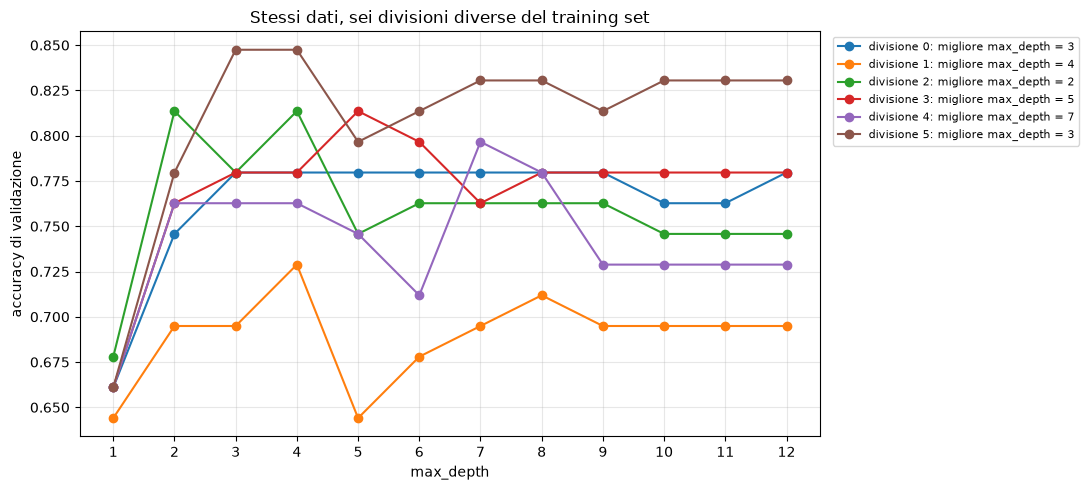

In [34]:
profondita = list(range(1, 13))

curve = []                                                # qui raccogliamo le sei curve
plt.figure(figsize=(11, 5))
for seme in range(6):
    # divido il TRAINING set in due: X_tr per addestrare, X_val per validare
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                                random_state=seme, stratify=y_train)
    acc_val = [accuracy_score(y_val, DecisionTreeClassifier(max_depth=d, random_state=0)
                                     .fit(X_tr, y_tr).predict(X_val))
               for d in profondita]                       # accuracy di validazione per ogni profondità
    curve.append(acc_val)
    migliore = profondita[int(np.argmax(acc_val))]        # la profondità con l'accuracy più alta
    plt.plot(profondita, acc_val, marker="o", label=f"divisione {seme}: migliore max_depth = {migliore}")

plt.xlabel("max_depth"); plt.ylabel("accuracy di validazione"); plt.xticks(profondita)
plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.grid(alpha=0.3)   # legenda fuori dal grafico
plt.title("Stessi dati, sei divisioni diverse del training set")
plt.tight_layout()
plt.show()

📌 Cambia solo **quali** pinguini finiscono nel validation set, eppure la profondità "migliore" va da 2 a 7: con 59 pinguini di validazione, pochi pinguini in più o in meno classificati bene bastano a cambiare la scelta.

🤔 **Allora quale profondità scelgo?** Pensaci prima di eseguire la cella successiva.

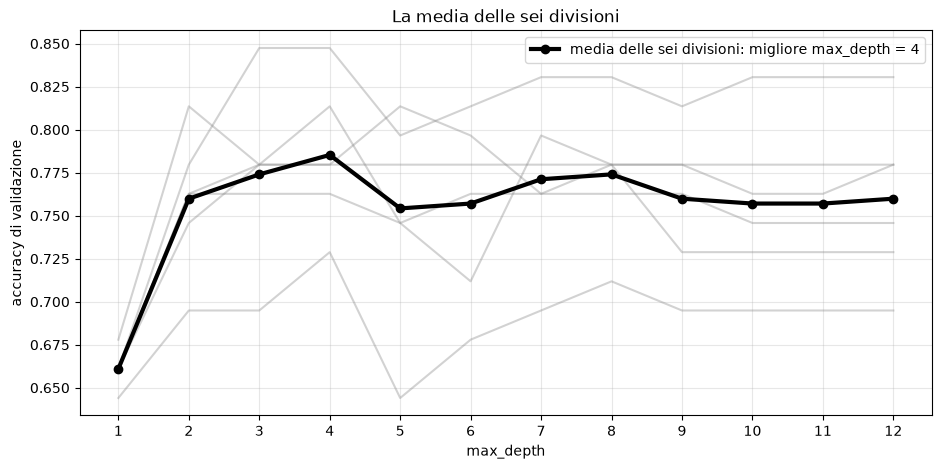

In [35]:
media = np.mean(curve, axis=0)                     # per ogni profondità, la media delle sei accuracy
migliore_media = profondita[int(np.argmax(media))]

plt.figure(figsize=(11, 5))
for acc_val in curve:
    plt.plot(profondita, acc_val, color="gray", alpha=0.35)          # le sei divisioni, in grigio
plt.plot(profondita, media, color="k", linewidth=3, marker="o",
         label=f"media delle sei divisioni: migliore max_depth = {migliore_media}")
plt.xlabel("max_depth"); plt.ylabel("accuracy di validazione"); plt.xticks(profondita)
plt.legend(); plt.grid(alpha=0.3); plt.title("La media delle sei divisioni")
plt.show()

Nessuna delle sei da sola: ognuna dipende da quali pinguini sono capitati nel validation set. Conviene **fare la media**: per ogni profondità, la media delle sei accuracy è una stima molto più stabile di una singola divisione. Qui la media premia `max_depth = 4`.

Le sei divisioni però sono estratte a caso, quindi si sovrappongono: alcuni pinguini sono finiti nel validation set più volte, altri mai. La **k-fold cross-validation** fa la stessa media in modo ordinato.

### 3.5 La k-fold cross-validation
La **k-fold cross-validation** divide il training set in $k$ parti (*fold*). A turno ogni fold fa da validation set e gli altri servono per addestrare: si ottengono $k$ punteggi, e se ne fa la media. Ogni pinguino del training set viene usato **una volta** per validare. Con $k = 5$:

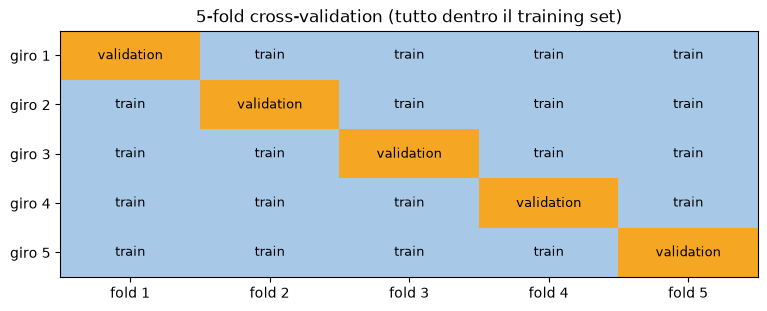

In [36]:
k = 5
schema = np.eye(k)                # matrice 5x5 con 1 sulla diagonale: il fold usato per la validazione

plt.figure(figsize=(9, 3.2))
plt.imshow(schema, aspect="auto", cmap=ListedColormap(["#A8C8E8", "#F5A623"]))   # 0 = azzurro, 1 = arancione
for i in range(k):
    for j in range(k):
        plt.text(j, i, "validation" if i == j else "train", ha="center", va="center", fontsize=9)
plt.xticks(range(k), [f"fold {j+1}" for j in range(k)])
plt.yticks(range(k), [f"giro {i+1}" for i in range(k)])
plt.title("5-fold cross-validation (tutto dentro il training set)")
plt.show()

In scikit-learn la divisione in fold la fa **`StratifiedKFold`**: *stratified* vuol dire che ogni fold ha la stessa proporzione di maschi e femmine del training set. **`cross_val_score`** fa da solo i $k$ addestramenti e restituisce i $k$ punteggi. Proviamolo su un albero qualsiasi, per esempio con `max_depth=3`:

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5 fold; shuffle=True mescola i pinguini prima di dividerli; random_state rende la divisione ripetibile
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

punteggi = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=0),   # il modello (non addestrato)
                           X_train, y_train,                                       # SOLO il training set
                           cv=cv)                                                  # come dividere
print("Che cosa restituisce:", type(punteggi))
print("Accuracy nei 5 fold:", punteggi.round(2))
print(f"Media: {punteggi.mean():.2f}  ± {punteggi.std():.2f} (deviazione standard)")

Che cosa restituisce: <class 'numpy.ndarray'>
Accuracy nei 5 fold: [0.83 0.77 0.74 0.83 0.83]
Media: 0.80  ± 0.04 (deviazione standard)


`cross_val_score` restituisce solo i punteggi di validazione. Se vogliamo anche l'accuracy di **training** di ogni giro (e i tempi), c'è **`cross_validate`**. In ognuno dei 5 giri:
1. addestra l'albero sui **4 fold di training** di quel giro;
2. `train_score`: l'accuracy sugli **stessi 4 fold** su cui ha appena imparato;
3. `test_score`: l'accuracy sul **fold di validazione** di quel giro, che l'albero non ha visto. Il nome è ingannevole: **non** è il nostro test set, che resta chiuso.

Restituisce un **dizionario** con un valore per giro.

> 🐍 Un **dizionario** associa delle **chiavi** a dei **valori**: `risultati["test_score"]` prende il valore della chiave `"test_score"`. `risultati.keys()` elenca le chiavi.

In [38]:
from sklearn.model_selection import cross_validate

risultati = cross_validate(DecisionTreeClassifier(random_state=0),   # l'albero senza limiti
                           X_train, y_train, cv=cv,
                           return_train_score=True)                  # calcola anche l'accuracy di training
print("Chiavi:", list(risultati.keys()))
print("train_score:", risultati["train_score"].round(2))    # accuracy sui 4 fold usati per addestrare
print("test_score: ", risultati["test_score"].round(2), " è il fold di validazione")     # accuracy sul fold di validazione
print(f"Media – training {risultati['train_score'].mean():.2f}, validazione {risultati['test_score'].mean():.2f}")

Chiavi: ['fit_time', 'score_time', 'test_score', 'train_score']
train_score: [1. 1. 1. 1. 1.]
test_score:  [0.87 0.64 0.79 0.8  0.78]  è il fold di validazione
Media – training 1.00, validazione 0.78


Training 1.00 in ogni giro e validazione molto più bassa: l'overfitting si vede senza toccare il test set.

Ora possiamo rispondere alla domanda della 3.4 con la cross-validation: per ogni profondità calcoliamo la media e la deviazione standard dei 5 punteggi.

In [39]:
righe = []
for d in range(1, 11):                      # le profondità da 1 a 10
    punteggi = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=0), X_train, y_train, cv=cv)
    righe.append({"max_depth": d, "accuracy CV media": punteggi.mean(), "deviazione std": punteggi.std()})

tabella_cv = pd.DataFrame(righe)
migliore_cv = tabella_cv.loc[tabella_cv["accuracy CV media"].idxmax()]   # .idxmax(): la riga con la media più alta
print(f"Migliore in cross-validation: max_depth = {migliore_cv['max_depth']:.0f}")
tabella_cv.round(3)

Migliore in cross-validation: max_depth = 5


,max_depth,accuracy CV media,deviazione std
0,1,0.635,0.037
1,2,0.794,0.028
2,3,0.799,0.036
3,4,0.790,0.036
4,5,0.815,0.052
5,6,0.781,0.056
6,7,0.785,0.070
7,8,0.777,0.076
8,9,0.773,0.069
9,10,0.768,0.067


La cross-validation sceglie `max_depth = 5` (0.815), mentre la media delle sei divisioni della 3.4 sceglieva 4. Ma da 2 a 5 le medie stanno tutte tra 0.790 e 0.815, e le differenze sono più piccole della deviazione standard tra i fold (tra 0.03 e 0.05): queste profondità sono **praticamente alla pari**, e quale vince dipende da come sono stati formati i fold. Due cose invece sono chiare: con `max_depth = 1` l'albero è troppo semplice (0.635, **underfitting**), e oltre 5 la media scende mentre la deviazione standard cresce (**overfitting**).

📌 Una differenza tra due punteggi di cross-validation conta solo se è più grande della loro deviazione standard. Quando sono alla pari, conviene l'albero più semplice.

Per un solo iperparametro basta questo ciclo. Con due o più iperparametri insieme però diventa un ciclo dentro un ciclo: scikit-learn lo fa per noi con **`GridSearchCV`**.

---
# Parte 4 — `GridSearchCV` passo per passo

`GridSearchCV` prova **tutte le combinazioni** di iperparametri che gli diamo, valuta ognuna con la cross-validation e tiene la migliore. Vediamolo un pezzo alla volta.

### 4.1 La griglia: iperparametro → valori da provare

In [40]:
from sklearn.model_selection import ParameterGrid

griglia_parametri = {                        # dizionario: nome dell'iperparametro → lista di valori
    "max_depth": list(range(1, 11)),         # 10 valori: 1, 2, ..., 10
    "min_samples_leaf": [1, 2, 5, 10, 20],   # 5 valori
}

combinazioni = list(ParameterGrid(griglia_parametri))   # tutte le combinazioni, una per riga
print("Le prime tre combinazioni:", combinazioni[:3])
print("Combinazioni:", len(combinazioni))
print("Fold:", cv.get_n_splits())
print("Addestramenti in cross-validation:", len(combinazioni) * cv.get_n_splits(), "(+ 1 finale, vedi 4.2)")

Le prime tre combinazioni: [{'max_depth': 1, 'min_samples_leaf': 1}, {'max_depth': 1, 'min_samples_leaf': 2}, {'max_depth': 1, 'min_samples_leaf': 5}]
Combinazioni: 50
Fold: 5
Addestramenti in cross-validation: 250 (+ 1 finale, vedi 4.2)


### 4.2 Creare la ricerca e addestrarla
`GridSearchCV` si usa come un modello: lo creo, poi chiamo `.fit()` **sul training set**.

In [41]:
from sklearn.model_selection import GridSearchCV

ricerca = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),   # il modello da mettere a punto
    param_grid=griglia_parametri,                       # le combinazioni da provare
    cv=cv,                                              # come fare la cross-validation (5 fold stratificati)
    scoring="accuracy",                                 # la misura con cui confrontarle
    return_train_score=True,                            # salva anche l'accuracy di training (serve in 4.3)
)                                                       # refit=True è il default: vedi sotto
ricerca.fit(X_train, y_train)                           # qui avvengono i 250 addestramenti

print("Iperparametri migliori (best_params_):", ricerca.best_params_)
print(f"Accuracy media in CV della migliore (best_score_): {ricerca.best_score_:.2f}")

Iperparametri migliori (best_params_): {'max_depth': 5, 'min_samples_leaf': 10}
Accuracy media in CV della migliore (best_score_): 0.82


Con `refit=True` (il default), dopo la ricerca `GridSearchCV` **riaddestra la combinazione migliore su tutto il training set**: il risultato è in `best_estimator_`, pronto per `.predict()`. Verifichiamolo addestrando a mano lo stesso albero:

In [42]:
albero_scelto = ricerca.best_estimator_          # l'albero migliore, già addestrato su tutto X_train

# lo stesso albero addestrato a mano su tutto il training set, con gli iperparametri migliori
a_mano = DecisionTreeClassifier(random_state=0, **ricerca.best_params_).fit(X_train, y_train)

print("Foglie dell'albero scelto:", albero_scelto.get_n_leaves())
print("Stesse predizioni dell'albero addestrato a mano?", (albero_scelto.predict(X_train) == a_mano.predict(X_train)).all())

Foglie dell'albero scelto: 13
Stesse predizioni dell'albero addestrato a mano? True


### 4.3 Tutti i risultati: `cv_results_`
`best_params_` dice solo chi ha vinto. Per vedere **tutte** le combinazioni c'è `cv_results_`: è un dizionario (una chiave per ogni informazione, un valore per ogni combinazione), che si trasforma facilmente in una tabella di pandas.

> 🐍 `pd.DataFrame(dizionario)` crea una tabella in cui ogni chiave diventa una colonna. `.sort_values("colonna")` ordina le righe; `tabella[[...]]` tiene solo alcune colonne.

In [43]:
risultati = pd.DataFrame(ricerca.cv_results_)
print("Colonne:", list(risultati.columns))

colonne_utili = ["params", "mean_test_score", "std_test_score", "rank_test_score", "mean_train_score"]
risultati[colonne_utili].sort_values("rank_test_score").head(8).round(3)

Colonne: ['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_max_depth', 'param_min_samples_leaf', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score', 'split0_train_score', 'split1_train_score', 'split2_train_score', 'split3_train_score', 'split4_train_score', 'mean_train_score', 'std_train_score']


,params,mean_test_score,std_test_score,rank_test_score,mean_train_score
23,"{'max_depth': 5, 'min_samples_leaf': 10}",0.824,0.037,1,0.853
28,"{'max_depth': 6, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
38,"{'max_depth': 8, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
33,"{'max_depth': 7, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
48,"{'max_depth': 10, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
43,"{'max_depth': 9, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
20,"{'max_depth': 5, 'min_samples_leaf': 1}",0.815,0.052,7,0.913
21,"{'max_depth': 5, 'min_samples_leaf': 2}",0.811,0.067,8,0.906


`mean_test_score` e `std_test_score` sono media e deviazione standard sui fold di **validazione**, `rank_test_score` la classifica (a pari merito, stesso rango), `mean_train_score` l'accuracy sui fold di training (c'è solo con `return_train_score=True`).

🤔 Guarda le prime righe: quanto distano dalla migliore? Più della deviazione standard o meno?

<details>
<summary><b>💡 Risposta</b> (clicca per aprire, ma prima prova a rispondere!)</summary>

Le prime sei combinazioni hanno tutte `min_samples_leaf = 10` e stanno tra 0.820 e 0.824: distano dalla migliore 0.004, molto meno della deviazione standard (circa 0.04). Sono **equivalenti**: `GridSearchCV` sceglie `max_depth = 5` perché ha la media più alta, ma vince per pochissimo. Come nella 3.5, prima di fidarsi della vincitrice conviene guardare quanto sono lontane le altre. Qui la scelta regge anche con la regola della 3.5: tra le sei equivalenti, `max_depth = 5` è l'albero meno profondo.

La tabella dice anche un'altra cosa: con `min_samples_leaf = 10` la profondità conta poco, perché nessuna foglia può avere meno di 10 pinguini e l'albero non riesce più a inseguire i singoli punti. Si vede da `mean_train_score`: con `min_samples_leaf = 10` l'accuracy di training resta intorno a 0.85–0.86, vicina a quella di validazione; con `max_depth = 5` e `min_samples_leaf = 1` sale a 0.91, ma la validazione scende a 0.815.

</details>

### 4.4 ⏩ Quando la griglia è troppo grande: `RandomizedSearchCV`
Gli addestramenti di una griglia sono il **prodotto** dei valori di ogni iperparametro per i fold: con tanti iperparametri diventano troppi. `RandomizedSearchCV` prova solo `n_iter` combinazioni **estratte a caso**, anche da **distribuzioni**: `randint(1, 21)` estrae un intero tra 1 e 20.

In [44]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint     # scipy: libreria scientifica, installata insieme a scikit-learn

distribuzioni = {
    "max_depth": randint(1, 21),          # interi da 1 a 20
    "min_samples_leaf": randint(1, 31),   # interi da 1 a 30
}
ricerca_casuale = RandomizedSearchCV(DecisionTreeClassifier(random_state=0), distribuzioni,
                                     n_iter=20,          # solo 20 combinazioni sulle 600 possibili
                                     cv=cv, random_state=0)
ricerca_casuale.fit(X_train, y_train)

combinazioni_possibili = 20 * 30                  # 20 valori di max_depth × 30 valori di min_samples_leaf
print("Combinazioni provate:", 20, "su", combinazioni_possibili)
print("Addestramenti in CV:", 20 * cv.get_n_splits(), "invece di", combinazioni_possibili * cv.get_n_splits())
print("Migliore:", ricerca_casuale.best_params_, f"→ CV {ricerca_casuale.best_score_:.2f}")

Combinazioni provate: 20 su 600
Addestramenti in CV: 100 invece di 3000
Migliore: {'max_depth': 14, 'min_samples_leaf': 9} → CV 0.81


Con 20 combinazioni su 600 trova un albero con accuracy in CV 0.81, quasi quanto la griglia della 4.2 (0.82), che ne provava 50. Con tanti iperparametri la ricerca casuale arriva vicino alla migliore con molti meno addestramenti.

### 4.5 🔓 Valutazione finale
Abbiamo scelto l'albero **senza mai guardare il test set**. Ora lo apriamo, una volta sola, per valutarlo. Accanto mettiamo l'albero senza limiti della 3.1, solo come riferimento: la scelta è già fatta.

Test – albero senza limiti:      0.77
Test – albero scelto (GridSearch): 0.84


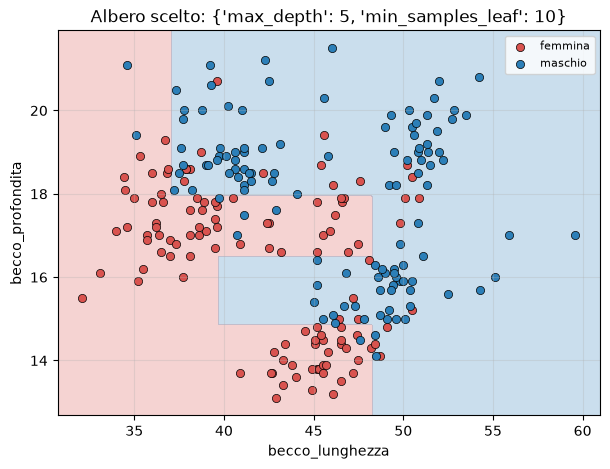

In [45]:
print(f"Test – albero senza limiti:      {accuracy_score(y_test, albero_libero.predict(X_test)):.2f}")
print(f"Test – albero scelto (GridSearch): {accuracy_score(y_test, albero_scelto.predict(X_test)):.2f}")
disegna_frontiera(albero_scelto, X_train, y_train, f"Albero scelto: {ricerca.best_params_}")

L'albero scelto fa 0.84 sul test set, contro 0.77 dell'albero senza limiti, e la sua frontiera non ha più isolette.

📌 La cross-validation aveva stimato 0.82, il test set dice 0.84: la stima era onesta. Con 100 pinguini di test ogni pinguino classificato bene o male sposta l'accuracy di 0.01, quindi una differenza di 0.02 è solo rumore.

---
# Riepilogo

| Concetto | Dove l'abbiamo visto | In scikit-learn |
|---|---|---|
| Errore quadratico medio | 2.2 | `mean_squared_error` |
| Regressione lineare | 2.3, 2.4, 2.6 | `LinearRegression`, `coef_`, `intercept_` |
| Feature categoriche | 2.6 | `pd.get_dummies` |
| Albero di regressione e overfitting | 2.7 | `DecisionTreeRegressor`, `max_depth` |
| Regressione per classificare | 2.10 | `LinearRegression` + soglia |
| Iperparametri dell'albero | 3.2 | `max_depth`, `min_samples_leaf`, `max_leaf_nodes`, `min_impurity_decrease`, `ccp_alpha` |
| Validation set e cross-validation | 3.4, 3.5 | `train_test_split`, `StratifiedKFold`, `cross_val_score`, `cross_validate` |
| Ricerca degli iperparametri | 4.1–4.3 | `GridSearchCV`: `best_params_`, `best_score_`, `best_estimator_`, `cv_results_` |
| Test set usato solo per il modello finale | 4.5 | 🔒 / 🔓 |